# Module 3 · Lab 3.2 — Project 3: Compliance Report Generator
## Banking compliance, built with Orchestrator-Worker + Evaluator-Optimizer

---

## Learning Objectives

By completing this lab, you will be able to:

1. **Implement the Orchestrator-Worker pattern** using LangGraph's `Send` API for dynamic parallel fan-out of report sections
2. **Build an Evaluator-Optimizer feedback loop** with 3-check validation (numerical accuracy, terminology compliance, cross-reference integrity) and a maximum of 3 revision iterations
3. **Use Parallelization** to fan out 5 specialist workers simultaneously and fan in their outputs through a keyed-upsert reducer, `Annotated[list, merge_drafts_by_name]`
4. **Integrate Human-in-the-Loop (HITL)** for compliance officer review using `interrupt()` and `Command(resume=...)`
5. **Apply PII redaction** to ensure no customer names or identifiers reach the LLM
6. **Generate regulatory-grade reports** for three different regulators (FinCEN, OCC, State Banking Dept) from a single system

---

## Where this sits

This is **Project 3**. It combines the LangGraph patterns from Module 2 — conditional routing (Lab 2.3), `Send` fan-out (Lab 2.5) and human-in-the-loop checkpoints (Lab 2.6) — and adds a grade-then-retry loop, all in one production-shaped system. The notebook is a complete, working build with its outputs saved: run it top to bottom and study how the pieces fit together.

---

## Architecture Overview

```
Template --> [Orchestrator] --> Send() --> [AML Worker]         --> [Evaluator] <--> [Workers] (max 3 loops)
                                      --> [KYC Worker]         -->
                                      --> [SAR Worker]         -->       |
                                      --> [Risk Worker]        --> [Synthesizer] --> [HITL Review] --> Final Report
                                      --> [Remediation Worker] -->
```

**Four agentic patterns in one graph:**
- **Orchestrator-Worker (#4):** The orchestrator reads the regulator template, plans sections, and dispatches workers
- **Parallelization (#3):** The `Send` API fans out 5+ workers simultaneously; the `merge_drafts_by_name` reducer fans results back in
- **Evaluator-Optimizer (#5):** Each section undergoes 3-check validation with up to 3 revision iterations
- **Human-in-the-Loop (#6):** `interrupt()` pauses the graph for compliance officer review before finalizing


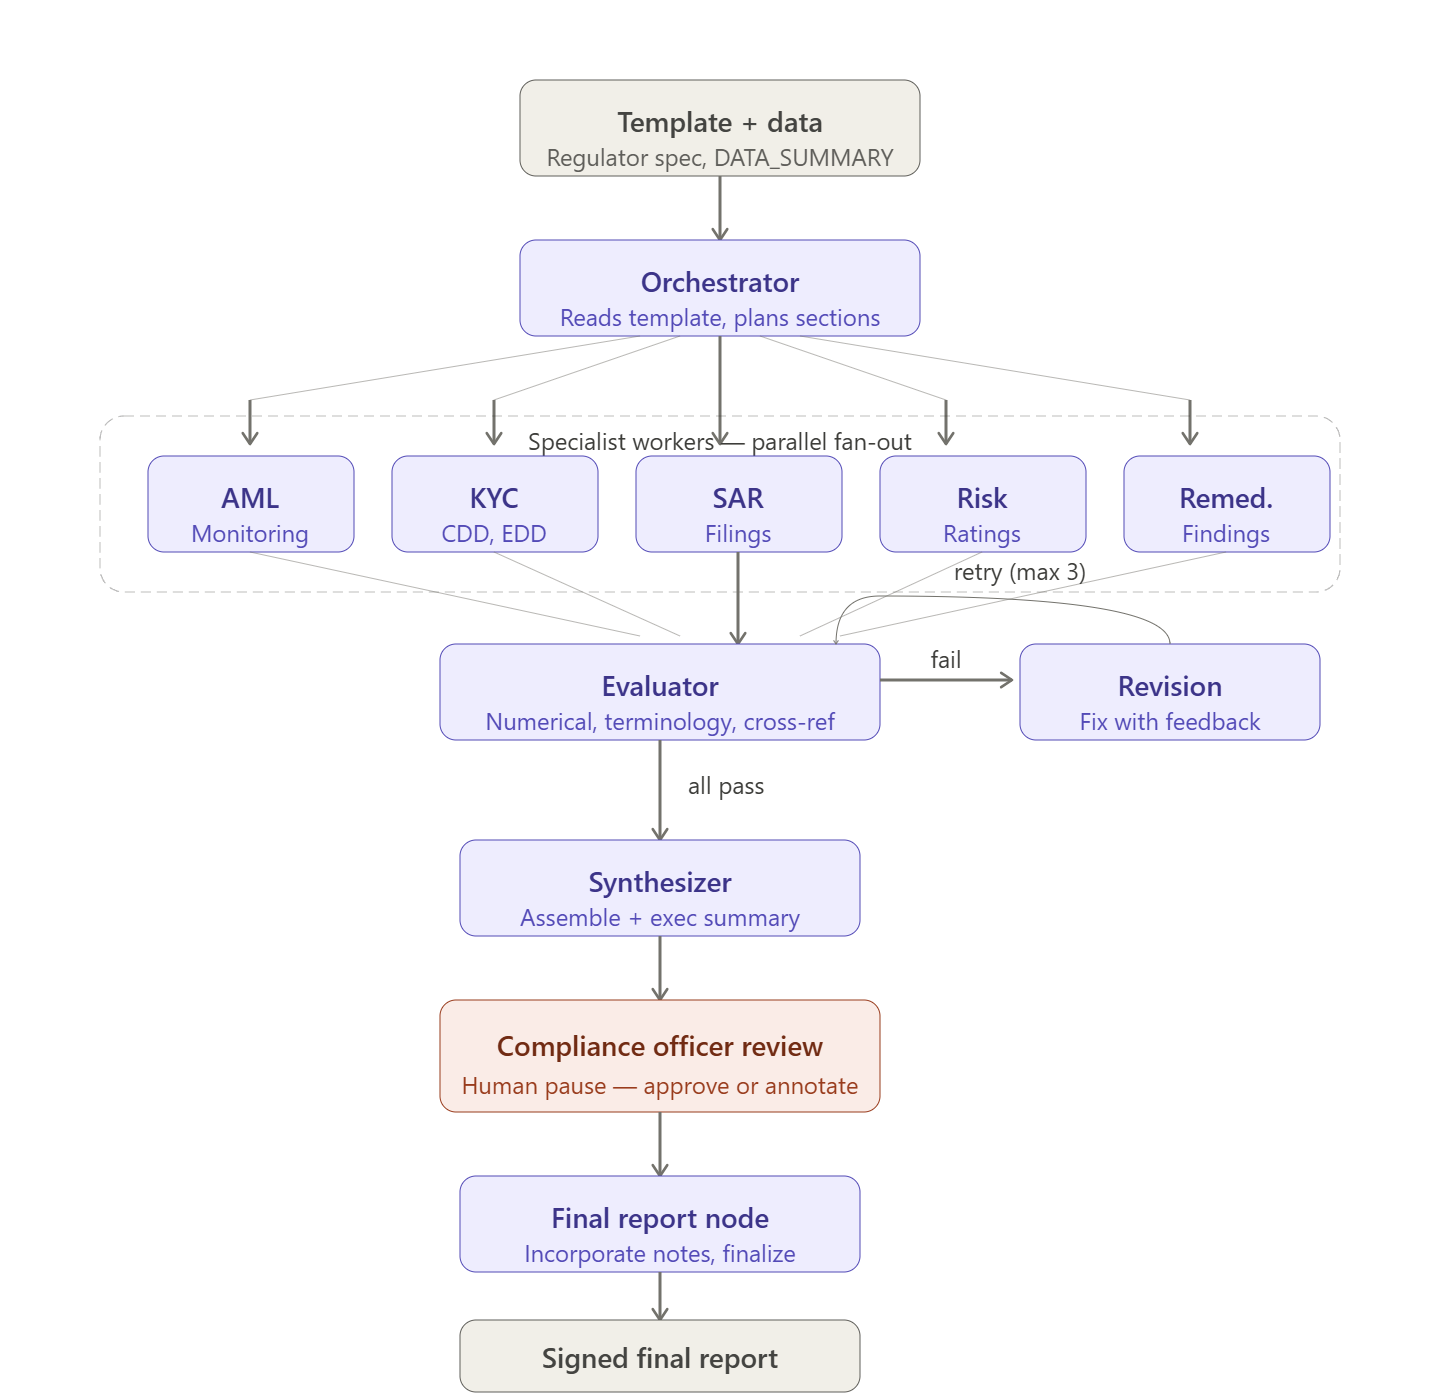

**Figure — The whole pipeline.** Template and data → the orchestrator plans the sections → specialist workers run in parallel → the evaluator checks numbers, terminology and cross-references, sending failures through a capped revision loop → the synthesizer assembles the report → a compliance officer reviews it → the signed final report.


---

## Models Used

| Role | Model | Temperature | Rationale |
|------|-------|-------------|----------|
| Orchestrator (planning) | `gpt-5-mini` | default (reasoning) | Needs strategic reasoning to map template sections to workers |
| Section Workers (writing) | `gpt-4.1-mini` | 0.2 | Needs slight creativity for natural regulatory prose |
| Evaluator (validation) | `gpt-5-mini` | default (reasoning) | Deterministic assessment of accuracy and compliance |
| Synthesizer (summary) | `gpt-4.1-mini` | 0.3 | Executive summary needs slightly more creative latitude |

---

## Section 1: Environment Setup

Install the required packages. We need:
- **LangChain v1+** and **langchain-openai v1+** for LLM integration
- **LangGraph v1+** for the stateful multi-agent graph with `Send`, `interrupt`, and `InMemorySaver`
- **pandas** for data analysis of CSV compliance data
- **pydantic** for structured output schemas

In [1]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-core langchain-openai langgraph pandas pydantic python-dotenv langsmith

from importlib.metadata import PackageNotFoundError, version

NOTEBOOK_PACKAGES = [
    "langchain",
    "langchain-core",
    "langchain-openai",
    "langgraph",
    "pandas",
    "pydantic",
    "python-dotenv",
    "langsmith",
]
for package_name in NOTEBOOK_PACKAGES:
    try:
        print(f"{package_name:<26} {version(package_name)}")
    except PackageNotFoundError:
        print(f"{package_name:<26} NOT INSTALLED — uncomment the !pip line above")

langchain                  1.4.3
langchain-core             1.6.6
langchain-openai           1.6.6
langgraph                  1.2.12
pandas                     2.3.3
pydantic                   2.12.5
python-dotenv              1.2.3
langsmith                  0.14.1


In [2]:
import os

# Where to get each key. Your instructor supplies the keys for this course; add each one to
# the course's .env file as KEY_NAME=value.
KEY_SIGNUP_PAGES = {
    "OPENAI_API_KEY": "supplied by your instructor (elsewhere: https://platform.openai.com/api-keys)",
    "TAVILY_API_KEY": "https://app.tavily.com (free tier)",
    "GROQ_API_KEY": "https://console.groq.com/keys (free tier)",
    "WEATHER_API_KEY": "https://www.weatherapi.com/signup.aspx (free tier)",
    "LANGSMITH_API_KEY": "https://smith.langchain.com -> Settings -> API Keys (free tier)",
    "ANTHROPIC_API_KEY": "https://console.anthropic.com/settings/keys",
    "GEMINI_API_KEY": "https://aistudio.google.com/app/apikey",
}


def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere).

    Prints one line per key, then stops with instructions if a required key is missing.

    Args:
        required: the environment-variable names this lab needs.
    """
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # the training VM, or any local machine
        from dotenv import find_dotenv, load_dotenv
        load_dotenv(find_dotenv(usecwd=True))        # searches upward for the course's .env file
        source = ".env / environment"
    print(f"\U0001F511 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")
    missing_keys = [key_name for key_name in required if not os.environ.get(key_name)]
    if missing_keys:
        instructions = "\n".join(
            f"  {key_name}: {KEY_SIGNUP_PAGES.get(key_name, 'see README.md at the top of the course folder')}"
            for key_name in missing_keys)
        raise RuntimeError(
            "This lab needs API keys that are not set yet. Add each one to\n"
            "the course's .env file as KEY_NAME=value, then re-run this cell:\n" + instructions)

load_keys(["OPENAI_API_KEY"])

# ---- Standard library ----
import os
import json
import operator
import re
from datetime import datetime
from typing import TypedDict, Annotated, Literal
import time

# ---- Data processing ----
import pandas as pd

# ---- Pydantic (structured output) ----
from pydantic import BaseModel, Field, field_validator

# ---- LangChain ----
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

# ---- LangGraph ----
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


print("All imports successful.")
print(f"Notebook started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

🔑 Key source: .env / environment
   OPENAI_API_KEY         ✅


All imports successful.
Notebook started: 2026-09-30 04:17:14


### Optional — trace the run in LangSmith

Set `ENABLE_LANGSMITH_TRACING = True` to send every step of this graph to LangSmith.
It needs your own `LANGSMITH_API_KEY` in `.env`. The cell clears LangSmith's
settings cache and **asserts** tracing is on, because a variable set after the first LangChain call is
otherwise silently ignored.

In [3]:
import langsmith

ENABLE_LANGSMITH_TRACING = False     # set True to trace this run in LangSmith

if ENABLE_LANGSMITH_TRACING:
    load_keys(["LANGSMITH_API_KEY"])
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "compliance-report-generator"
    # LangSmith caches both settings on the first LangChain call — clear the cache so they apply.
    langsmith.utils.get_env_var.cache_clear()
    langsmith.utils.get_tracer_project.cache_clear()
    assert langsmith.utils.tracing_is_enabled(), "tracing is still off — check LANGSMITH_API_KEY"
    print(f"LangSmith tracing ON -> project {langsmith.utils.get_tracer_project()!r}")
else:
    print("LangSmith tracing is off. Set ENABLE_LANGSMITH_TRACING = True to trace this run.")

LangSmith tracing is off. Set ENABLE_LANGSMITH_TRACING = True to trace this run.


---

## Section 2: Business Scenario --- MidwestBank Compliance Challenge

> **You have already built the skeleton.** Lab 2.5 (Part 5) used the `Send` API to plan report
> sections and fan out one worker per section — that is the same orchestrator-worker backbone used
> here, and it is deliberately *not* the new material in this project. What this project adds is
> everything that separates a demo from a system a regulator would accept:
>
> | Lab 2.5 taught | This project adds |
> |---|---|
> | Sections invented by the LLM from a topic string | Sections planned from a real **regulator template** (FinCEN / OCC / state) |
> | Prose with plausible-sounding numbers | Every figure grounded in **eight pre-provided data files** via `DATA_SUMMARY` — the model never invents a statistic |
> | `operator.add` — workers append | **`merge_drafts_by_name`** keyed-upsert — a revised draft *replaces* its predecessor instead of duplicating it |
> | One pass, whatever comes out | **Evaluator-optimizer** loop: each draft scored against a rubric and revised, with a retry cap |
> | Nobody checks the output | **Human-in-the-loop** — a compliance officer reviews and signs off before anything ships |



### The Institution

**MidwestBank** is a mid-size U.S. commercial bank headquartered in Kansas City, Missouri:
- **Total assets:** $8 billion
- **Employees:** 500 across 42 branches
- **Customers:** 5,000+ active accounts
- **Primary regulators:** FinCEN (BSA/AML), OCC (safety & soundness), State Banking Department

### The Problem: Quarterly Report Generation

MidwestBank's 6-person compliance team faces a recurring crisis every quarter:

| Pain Point | Current Reality |
|------------|----------------|
| **Manual data extraction** | Pull data from 5 separate systems (core banking, AML platform, KYC database, SAR system, risk engine) |
| **Report assembly time** | 4 full weeks per quarterly cycle for 3 different regulators |
| **Numerical errors** | 8-12 copy-paste errors per report (wrong totals, stale percentages) |
| **Terminology drift** | Inconsistent use of regulatory terms across sections (e.g., mixing "CDD" and "KYC" incorrectly) |
| **Cross-reference failures** | Section 2 may cite a number that contradicts Section 5 |
| **Regulatory risk** | Q2 2024 error triggered a formal inquiry, costing 200+ hours of remediation |

### The Solution: AI-Powered Compliance Report Generator

We will build a LangGraph-based system that:

1. **Reads** the regulator's template and dynamically plans which sections to generate
2. **Dispatches** 5 specialist workers (AML, KYC, SAR, Risk, Remediation) in **parallel**
3. **Evaluates** each section for numerical accuracy, terminology compliance, and cross-reference integrity
4. **Iterates** up to 3 times per section until quality passes all checks
5. **Pauses** for a compliance officer to review the final report before submission

### Expected Outcomes

| Metric | Before | After |
|--------|--------|-------|
| Report generation time | 4 weeks | 30 minutes |
| Numerical errors | 8-12 per report | 0 (evaluator-verified) |
| Terminology consistency | Manual spot-checks | 100% automated |
| Cross-reference integrity | Occasional failures | Guaranteed |
| Compliance officer time | 120 hours/quarter | 2 hours (review only) |

---

## Section 3: Load All Compliance Data

We load 8 data files from the `Lab_3.2 Files` folder next to this notebook. Together they represent MidwestBank's compliance data ecosystem:

| File | Format | Records | Description |
|------|--------|---------|-------------|
| `customers.csv` | CSV | 5,000 | Customer master with KYC status, risk scores, PEP flags |
| `transactions.csv` | CSV | 50,000 | Transaction ledger with suspicious activity flags |
| `sar_filings.csv` | CSV | 250 | Suspicious Activity Reports filed with FinCEN |
| `prior_findings.csv` | CSV | 40 | Regulatory examination findings and remediation status |
| `regulatory_thresholds.json` | JSON | --- | BSA/AML thresholds (CTR $10K, SAR thresholds, KYC cycles) |
| `fincen_template.md` | Markdown | 10 sections | FinCEN quarterly BSA/AML report template |
| `occ_template.md` | Markdown | 10 parts | OCC examination report template |
| `state_template.md` | Markdown | 12 sections | State banking department report template |

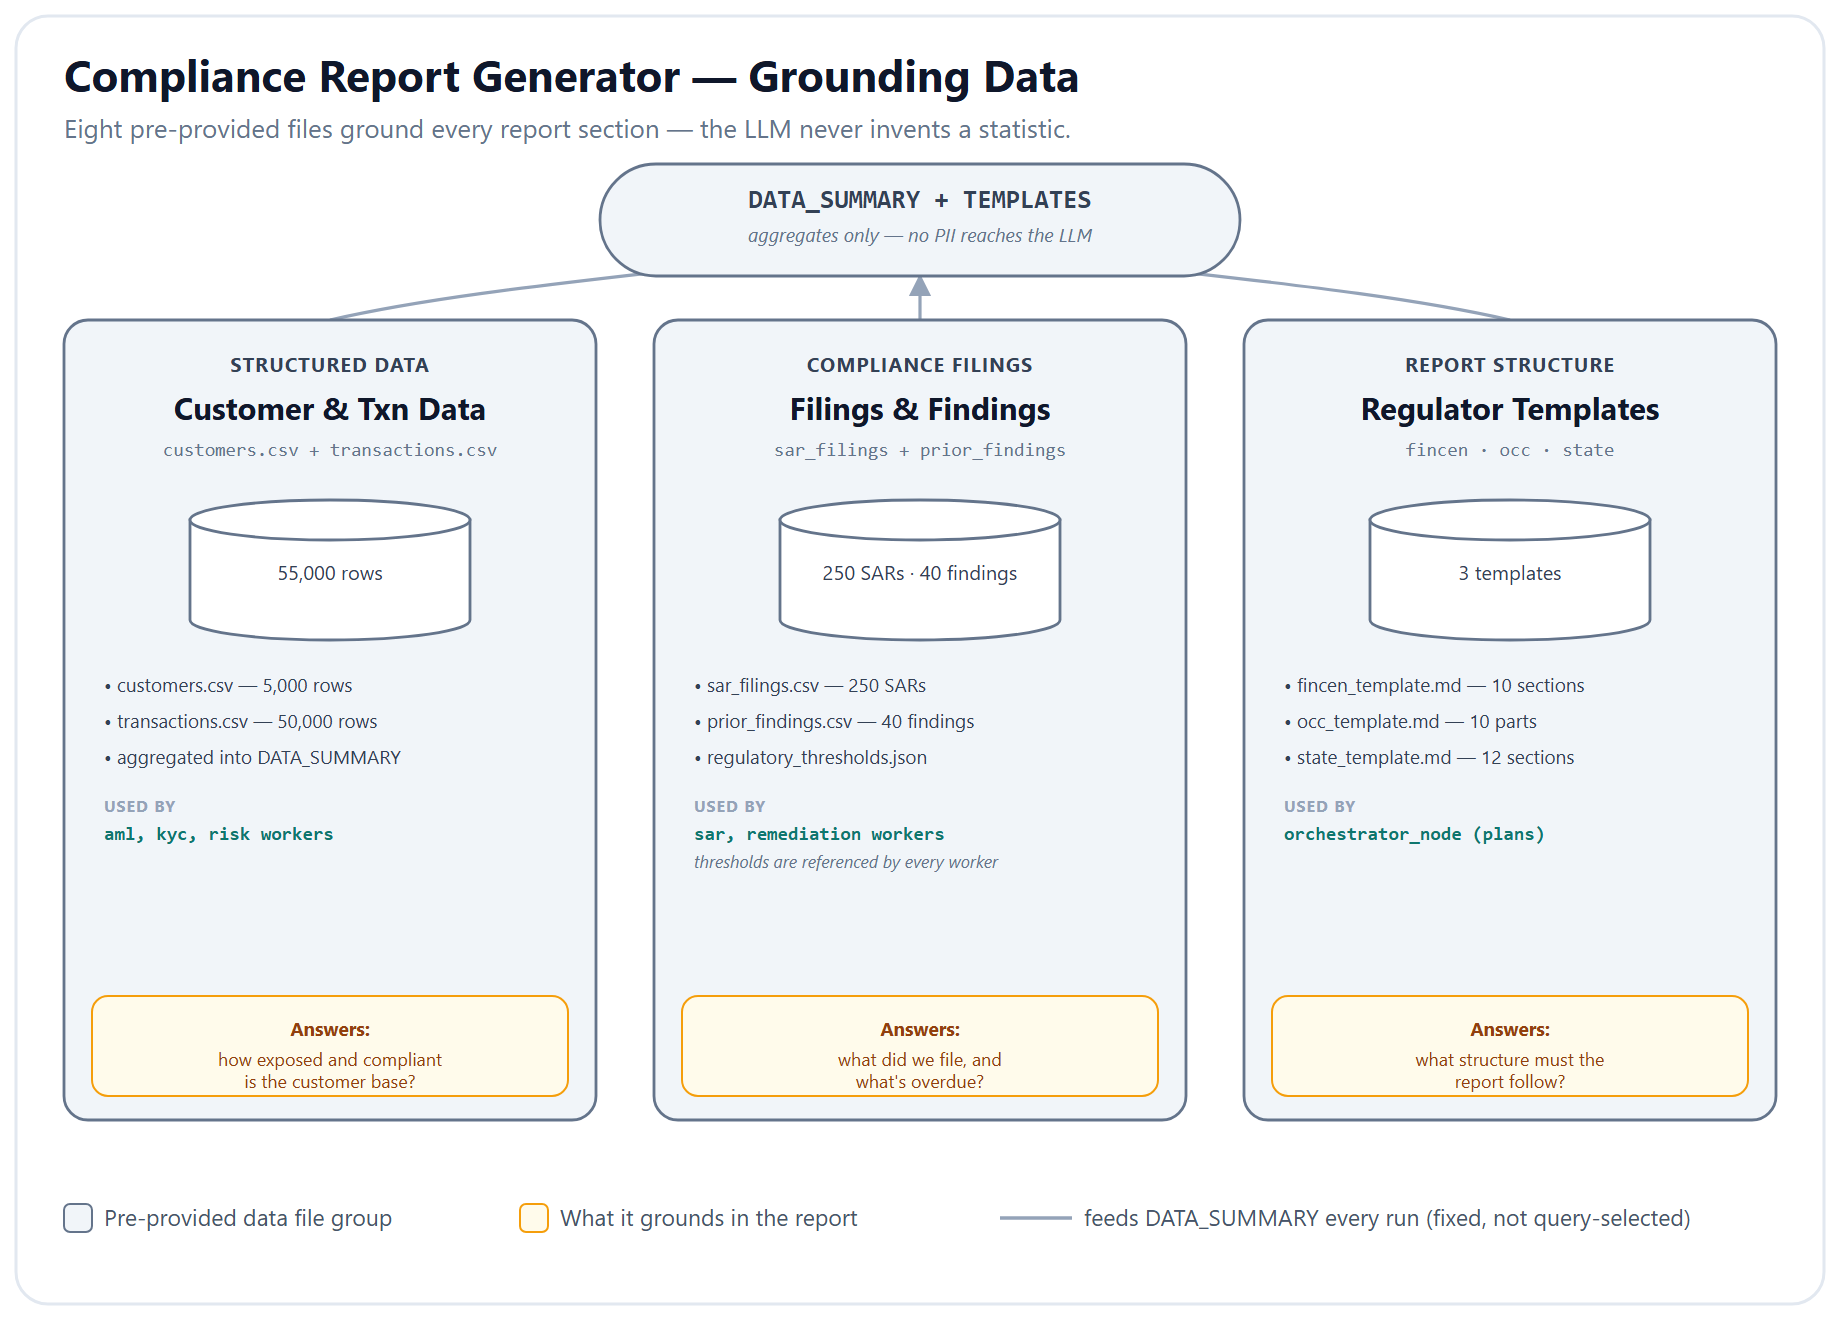

**Figure — Real numbers in, real numbers out.** Every statistic a worker cites comes from `DATA_SUMMARY`, pre-computed from these eight files before any LLM call — never from the model's imagination.

In [4]:
# ---- The data files sit in the "Lab_3.2 Files" folder next to this notebook ----
DATA_FOLDER = "Lab_3.2 Files"

# ---- Load CSV data files ----
customers_dataframe = pd.read_csv(f"{DATA_FOLDER}/customers.csv")
transactions_dataframe = pd.read_csv(f"{DATA_FOLDER}/transactions.csv")
sar_dataframe = pd.read_csv(f"{DATA_FOLDER}/sar_filings.csv")
findings_dataframe = pd.read_csv(f"{DATA_FOLDER}/prior_findings.csv")

# ---- Load JSON thresholds ----
with open(f"{DATA_FOLDER}/regulatory_thresholds.json") as thresholds_file:
    thresholds = json.load(thresholds_file)

# ---- Load report templates ----
with open(f"{DATA_FOLDER}/fincen_template.md") as fincen_template_file:
    fincen_template = fincen_template_file.read()

with open(f"{DATA_FOLDER}/occ_template.md") as occ_template_file:
    occ_template = occ_template_file.read()

with open(f"{DATA_FOLDER}/state_template.md") as state_template_file:
    state_template = state_template_file.read()

# ---- Store templates in a lookup dict ----
TEMPLATES = {
    "FinCEN": fincen_template,
    "OCC": occ_template,
    "State": state_template,
}

# ---- Print summary statistics ----
print("=" * 70)
print("MIDWESTBANK DATA SUMMARY")
print("=" * 70)
print(f"\nCustomers:     {len(customers_dataframe):>8,} records  | Columns: {list(customers_dataframe.columns)}")
print(f"Transactions:  {len(transactions_dataframe):>8,} records  | Columns: {list(transactions_dataframe.columns)}")
print(f"SAR Filings:   {len(sar_dataframe):>8,} records  | Columns: {list(sar_dataframe.columns)}")
print(f"Prior Findings:{len(findings_dataframe):>8,} records  | Columns: {list(findings_dataframe.columns)}")
print(f"\nRegulatory Thresholds: {len(thresholds)} top-level keys")
print(f"Templates loaded: {list(TEMPLATES.keys())}")
print(f"  - FinCEN: {len(fincen_template):,} chars")
print(f"  - OCC:    {len(occ_template):,} chars")
print(f"  - State:  {len(state_template):,} chars")

MIDWESTBANK DATA SUMMARY

Customers:        5,000 records  | Columns: ['customer_id', 'name', 'dob', 'nationality', 'risk_score', 'kyc_status', 'kyc_last_verified', 'account_type', 'pep_flag']
Transactions:    50,000 records  | Columns: ['txn_id', 'date', 'sender_account', 'receiver_account', 'amount', 'currency', 'txn_type', 'is_suspicious', 'SAR_filed']
SAR Filings:        250 records  | Columns: ['sar_id', 'customer_id', 'filing_date', 'suspicious_activity_type', 'amount_involved', 'narrative', 'status']
Prior Findings:      40 records  | Columns: ['finding_id', 'regulator', 'finding_date', 'category', 'severity', 'description', 'remediation_status', 'remediation_deadline']

Regulatory Thresholds: 11 top-level keys
Templates loaded: ['FinCEN', 'OCC', 'State']
  - FinCEN: 5,406 chars
  - OCC:    5,530 chars
  - State:  6,769 chars


In [5]:
# ---- Quick look at sample rows from each dataset ----
print("--- Customers (first 3 rows) ---")
display(customers_dataframe.head(3))

print("\n--- Transactions (first 3 rows) ---")
display(transactions_dataframe.head(3))

print("\n--- SAR Filings (first 3 rows) ---")
display(sar_dataframe.head(3))

print("\n--- Prior Findings (first 3 rows) ---")
display(findings_dataframe.head(3))

--- Customers (first 3 rows) ---


,customer_id,name,dob,nationality,risk_score,kyc_status,kyc_last_verified,account_type,pep_flag
0,CUST-000001,Christopher Brown,2006-11-13,US,low,expired,2024-09-16,checking,False
1,CUST-000002,Mary Smith,2002-12-13,US,medium,verified,2024-06-01,investment,False
2,CUST-000003,Charles Rodriguez,1957-04-11,US,low,verified,2025-08-20,business,False



--- Transactions (first 3 rows) ---


,txn_id,date,sender_account,receiver_account,amount,currency,txn_type,is_suspicious,SAR_filed
0,TXN-00000001,2025-05-05,CUST-000913,CUST-000205,1232.01,USD,ATM,False,False
1,TXN-00000002,2025-06-22,CUST-000713,CUST-004838,158.69,USD,withdrawal,False,False
2,TXN-00000003,2026-03-15,CUST-004598,CUST-001629,3509.61,USD,withdrawal,False,False



--- SAR Filings (first 3 rows) ---


,sar_id,customer_id,filing_date,suspicious_activity_type,amount_involved,narrative,status
0,SAR-0001,CUST-000913,2026-03-16,Rapid movement of funds,252442.94,Suspicious activity detected: Rapid movement o...,closed
1,SAR-0002,CUST-000840,2025-04-16,Trade-based money laundering,96069.44,Alert generated for trade-based money launderi...,filed
2,SAR-0003,CUST-000245,2026-02-09,Round dollar amounts,240334.28,Customer CUST-000245 engaged in round dollar a...,closed



--- Prior Findings (first 3 rows) ---


,finding_id,regulator,finding_date,category,severity,description,remediation_status,remediation_deadline
0,FIND-0001,State Banking Dept,2025-07-13,AML/BSA,significant,AML policy not updated to reflect regulatory c...,in_progress,2025-10-08
1,FIND-0002,FinCEN,2025-08-01,Customer Due Diligence,significant,CDD procedures not commensurate with customer ...,overdue,2025-09-08
2,FIND-0003,FinCEN,2025-08-19,KYC,minor,KYC verification procedures not consistently a...,in_progress,2026-02-04


---

## Section 4: Data Analysis Helpers --- Pre-Compute Key Statistics

Before any data reaches the LLM, we pre-compute all the statistics that workers will cite in their report sections. This serves two critical purposes:

1. **Accuracy:** Workers reference verified numbers from `DATA_SUMMARY` rather than hallucinating statistics
2. **PII protection:** Only aggregate statistics are passed to the LLM --- never raw customer records

The evaluator will later validate that every number in a drafted section matches `DATA_SUMMARY`.

In [6]:
# =====================================================================
# PRE-COMPUTE ALL STATISTICS THAT WORKERS WILL NEED
# =====================================================================

# ---- AML / Transaction Monitoring Statistics ----
total_transaction_count = int(len(transactions_dataframe))
total_transaction_amount = float(transactions_dataframe["amount"].sum())
suspicious_transactions = transactions_dataframe[transactions_dataframe["is_suspicious"] == True]
suspicious_count = int(len(suspicious_transactions))
suspicious_percentage = float(round(suspicious_count / total_transaction_count * 100, 2))
suspicious_amount = float(suspicious_transactions["amount"].sum())

# Transactions above CTR threshold ($10,000)
ctr_threshold = float(thresholds["ctr_threshold"]["amount"])
ctr_eligible = transactions_dataframe[transactions_dataframe["amount"] >= ctr_threshold]
ctr_count = int(len(ctr_eligible))

# Transaction types breakdown
transaction_type_counts = {str(label): int(count)
                           for label, count in transactions_dataframe["txn_type"].value_counts().to_dict().items()}

# ---- SAR Filing Statistics ----
sar_total = int(len(sar_dataframe))
sar_total_amount = float(sar_dataframe["amount_involved"].sum())
sar_by_type = {str(label): int(count)
               for label, count in sar_dataframe["suspicious_activity_type"].value_counts().to_dict().items()}
sar_by_status = {str(label): int(count)
                 for label, count in sar_dataframe["status"].value_counts().to_dict().items()}

# ---- KYC / CDD Statistics ----
kyc_status_distribution = {str(label): int(count)
                           for label, count in customers_dataframe["kyc_status"].value_counts().to_dict().items()}
kyc_verified_count = int(kyc_status_distribution.get("verified", 0))
kyc_verified_percentage = float(round(kyc_verified_count / len(customers_dataframe) * 100, 2))
kyc_expired_count = int(kyc_status_distribution.get("expired", 0))
kyc_pending_count = int(kyc_status_distribution.get("pending", 0))

# PEP (Politically Exposed Person) statistics
pep_count = int(customers_dataframe[customers_dataframe["pep_flag"] == True].shape[0])

# ---- Risk Score Distribution ----
risk_distribution = {str(label): int(count)
                     for label, count in customers_dataframe["risk_score"].value_counts().to_dict().items()}
high_risk_count = int(risk_distribution.get("high", 0))
medium_risk_count = int(risk_distribution.get("medium", 0))
low_risk_count = int(risk_distribution.get("low", 0))

# ---- Account Type Distribution ----
account_type_distribution = {str(label): int(count)
                             for label, count in customers_dataframe["account_type"].value_counts().to_dict().items()}

# ---- Prior Findings / Remediation Statistics ----
findings_total = int(len(findings_dataframe))
findings_by_category = {str(label): int(count)
                        for label, count in findings_dataframe["category"].value_counts().to_dict().items()}
findings_by_severity = {str(label): int(count)
                        for label, count in findings_dataframe["severity"].value_counts().to_dict().items()}
findings_by_status = {str(label): int(count)
                      for label, count in findings_dataframe["remediation_status"].value_counts().to_dict().items()}
findings_by_regulator = {str(label): int(count)
                         for label, count in findings_dataframe["regulator"].value_counts().to_dict().items()}

# Overdue remediations
overdue_findings = findings_dataframe[findings_dataframe["remediation_status"] == "overdue"]
overdue_count = int(len(overdue_findings))

# =====================================================================
# ASSEMBLE INTO A SINGLE DATA_SUMMARY DICTIONARY
# =====================================================================

DATA_SUMMARY = {
    "institution": {
        "name": "MidwestBank",
        "total_assets": "$8 billion",
        "employees": 500,
        "branches": 42,
    },
    "aml_monitoring": {
        "total_transactions": total_transaction_count,
        "total_transaction_amount": float(round(total_transaction_amount, 2)),
        "suspicious_transactions": suspicious_count,
        "suspicious_percentage": suspicious_percentage,
        "suspicious_amount": float(round(suspicious_amount, 2)),
        "ctr_eligible_transactions": ctr_count,
        "ctr_threshold": ctr_threshold,
        "transaction_types": transaction_type_counts,
    },
    "sar_filings": {
        "total_sars": sar_total,
        "total_amount_involved": float(round(sar_total_amount, 2)),
        "by_activity_type": sar_by_type,
        "by_status": sar_by_status,
    },
    "kyc_cdd": {
        "total_customers": int(len(customers_dataframe)),
        "kyc_verified": kyc_verified_count,
        "kyc_verified_pct": kyc_verified_percentage,
        "kyc_expired": kyc_expired_count,
        "kyc_pending": kyc_pending_count,
        "kyc_status_distribution": kyc_status_distribution,
        "pep_customers": pep_count,
        "account_types": account_type_distribution,
    },
    "risk_assessment": {
        "high_risk": high_risk_count,
        "medium_risk": medium_risk_count,
        "low_risk": low_risk_count,
        "risk_distribution": risk_distribution,
    },
    "remediation": {
        "total_findings": findings_total,
        "by_category": findings_by_category,
        "by_severity": findings_by_severity,
        "by_status": findings_by_status,
        "by_regulator": findings_by_regulator,
        "overdue_count": overdue_count,
        "overdue_details": overdue_findings[["finding_id", "category", "severity", "remediation_deadline"]].to_dict(orient="records") if overdue_count > 0 else [],
    },
}

# ---- Print the summary for verification ----
print("=" * 70)
print("DATA_SUMMARY (passed to workers --- NO PII, only aggregates)")
print("=" * 70)
for section, stats in DATA_SUMMARY.items():
    print(f"\n>> {section.upper()}")
    for stat_name, stat_value in stats.items():
        print(f"   {stat_name}: {stat_value}")


DATA_SUMMARY (passed to workers --- NO PII, only aggregates)

>> INSTITUTION
   name: MidwestBank
   total_assets: $8 billion
   employees: 500
   branches: 42

>> AML_MONITORING
   total_transactions: 50000
   total_transaction_amount: 311260070.15
   suspicious_transactions: 1053
   suspicious_percentage: 2.11
   suspicious_amount: 5214006.53
   ctr_eligible_transactions: 4347
   ctr_threshold: 10000.0
   transaction_types: {'transfer': 8578, 'deposit': 8449, 'ATM': 8361, 'check': 8332, 'withdrawal': 8211, 'wire': 8069}

>> SAR_FILINGS
   total_sars: 250
   total_amount_involved: 123064246.65
   by_activity_type: {'Round dollar amounts': 28, 'Currency exchange patterns': 27, 'Unusual wire transfer pattern': 27, 'Rapid movement of funds': 26, 'Trade-based money laundering': 26, 'Large cash deposits': 25, 'Structuring (smurfing)': 24, 'Shell company indicators': 24, 'High-risk jurisdiction transfer': 23, 'Inconsistent with customer profile': 20}
   by_status: {'under_review': 85, 'file

---

## Section 5: PII Redaction Layer

> Same principle as any PII layer: nothing identifying ever reaches the LLM.
> Notice how the *policy* changes, because redaction rules are always
> domain-specific:
>
> | | A customer-support agent | Here (banking compliance) |
> |---|---|---|
> | Redacted | customer names, e-mail addresses | customer names, `CUST-` account IDs |
> | Deliberately **kept** | order IDs — needed to answer the ticket | **`SAR-` filing IDs** — regulatory references, not PII |
> | Restored afterwards? | yes — the real name goes back into the customer's reply | **no** — a filed report must never re-inject customer identities |

Workers here operate exclusively on the pre-computed `DATA_SUMMARY` (aggregates only), so this layer
is **defense-in-depth**: a safety net over text that should already be clean.

In [7]:
def redact_pii(text: str) -> str:
    """
    Defense-in-depth PII redaction. Removes customer IDs and names
    from any text before it is sent to the LLM.

    Patterns redacted:
    - Customer IDs (CUST-XXXXXX)
    - SAR IDs are kept (SAR-XXXX) because they are filing identifiers, not PII
    - Names matching the customer database
    """
    # Redact customer IDs
    text = re.sub(r"CUST-\d{6}", "[REDACTED-CUSTOMER-ID]", text)

    # Redact any customer names from the database
    # Build a set of all names for fast lookup
    all_names = set(customers_dataframe["name"].dropna().unique())
    for name in all_names:
        if name in text:
            text = text.replace(name, "[REDACTED-NAME]")

    return text


# ---- Quick test ----
test_text = "Customer CUST-000001 (Christopher Brown) made a suspicious transfer."
print(f"Before: {test_text}")
print(f"After:  {redact_pii(test_text)}")

Before: Customer CUST-000001 (Christopher Brown) made a suspicious transfer.
After:  Customer [REDACTED-CUSTOMER-ID] ([REDACTED-NAME]) made a suspicious transfer.


---

## Section 6: State Definitions

This system uses **two separate state schemas** --- a critical architectural decision that enables the `Send` API pattern.

### Why Two States?

| State | Who Uses It | Purpose |
|-------|-------------|--------|
| `ComplianceReportState` | Orchestrator, Evaluator, Synthesizer, HITL | The **main graph state** --- tracks the full report lifecycle |
| `WorkerState` | Section workers (via `Send()`) | The **per-worker state** --- each `Send()` call creates an independent instance |

The key insight is the **`Annotated[list, merge_drafts_by_name]` reducer**. When multiple workers run in parallel, each returns `{"section_drafts": [their_draft]}`. The `merge_drafts_by_name` reducer **automatically merges** these lists into the main state, one entry per `section_name` — so a *revised* draft replaces its predecessor, where plain `operator.add` would append it beside the original. Without a reducer, LangGraph rejects the parallel writes (`InvalidUpdateError`: a plain field can receive only one value per step).

```
Worker 1 returns: {"section_drafts": [draft_A]}
Worker 2 returns: {"section_drafts": [draft_B]}     --> Reducer combines: [draft_A, draft_B, draft_C]
Worker 3 returns: {"section_drafts": [draft_C]}
```

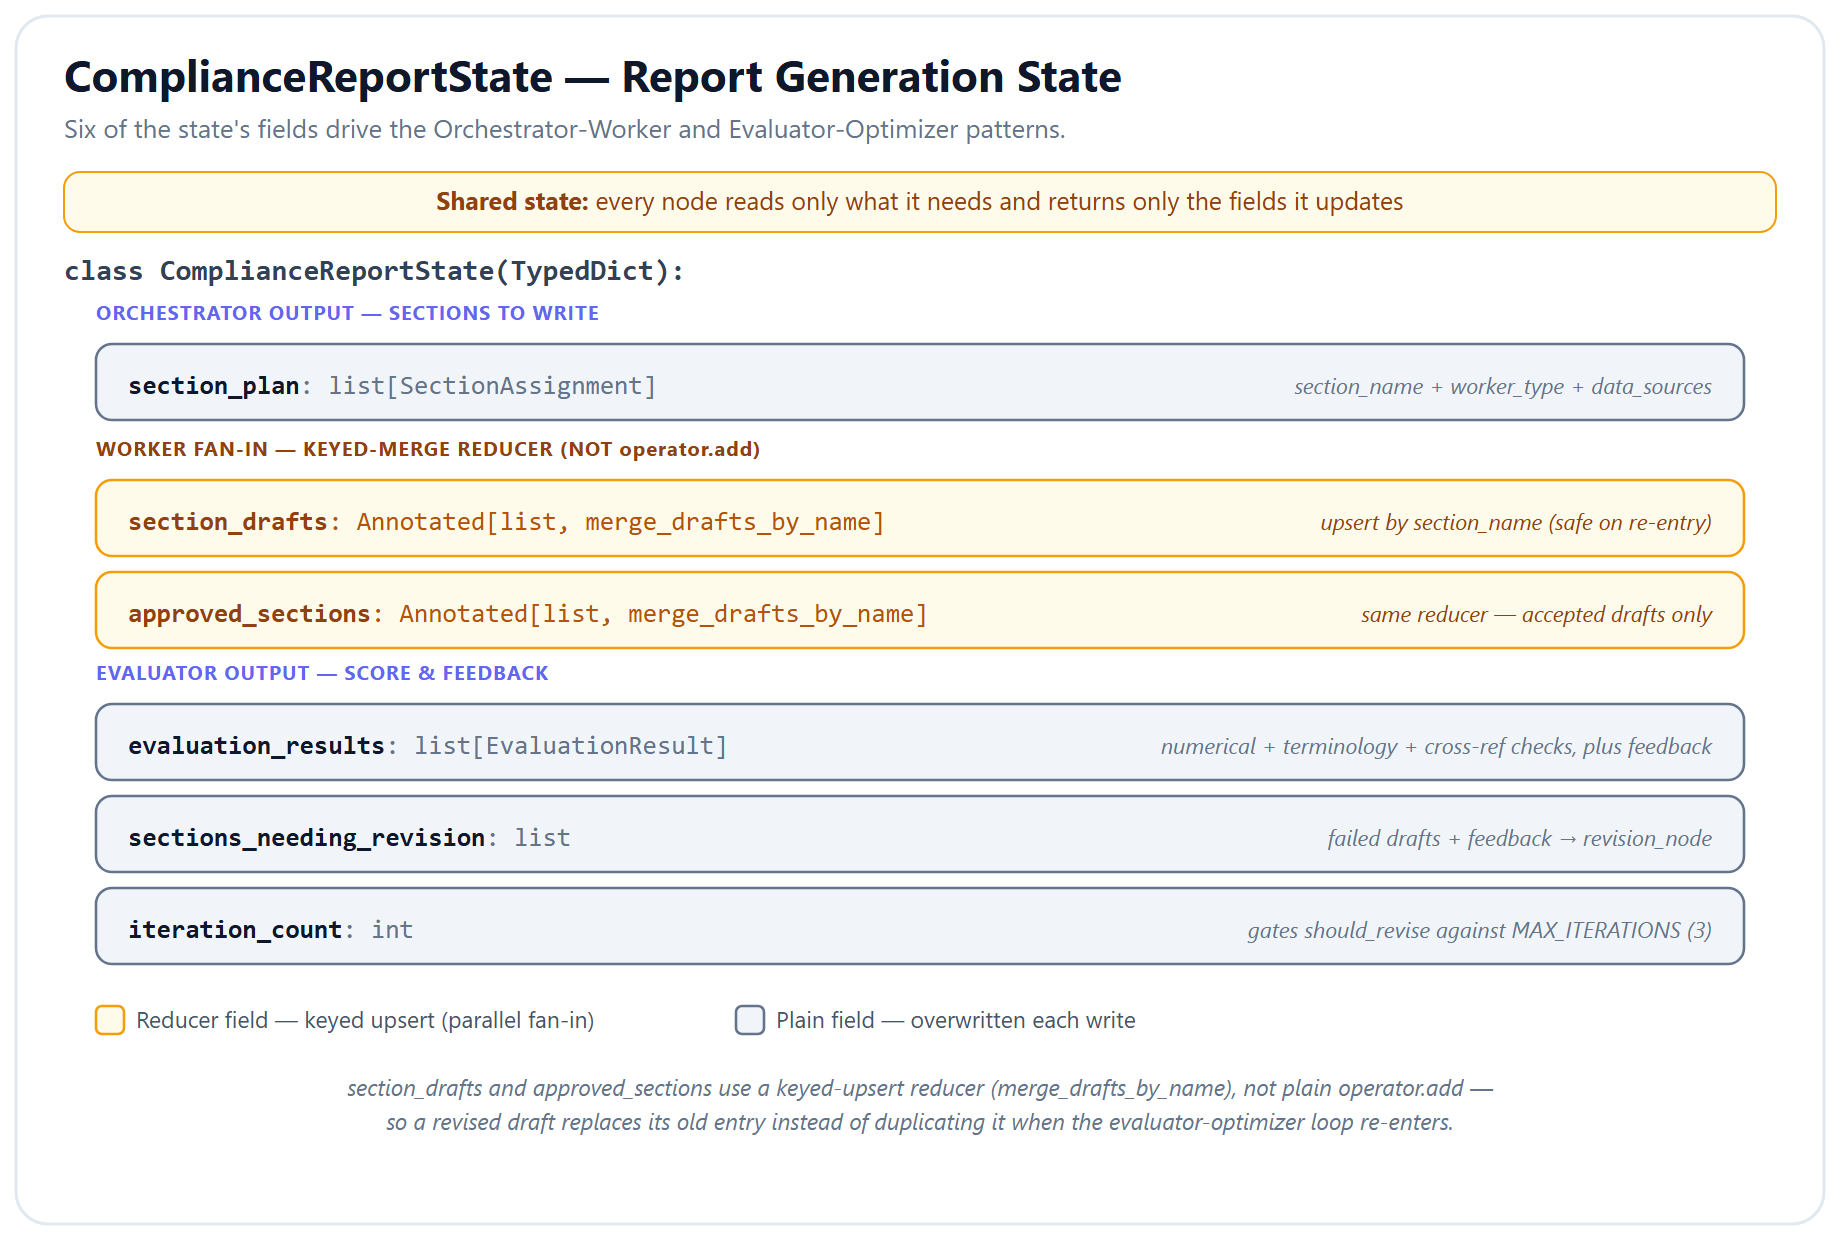

**Figure — ComplianceReportState: one state, two reducer styles.** `section_drafts` and `approved_sections` use a keyed-upsert reducer instead of plain `operator.add`, so a revised draft replaces its old entry instead of duplicating it on every pass through the loop.

In [8]:
# =====================================================================
# MAIN GRAPH STATE --- used by orchestrator, evaluator, synthesizer
# =====================================================================

def merge_drafts_by_name(existing_drafts: list, new_drafts: list) -> list:
    """Upsert reducer keyed on `section_name`.

    - Fan-in from parallel workers: each Send returns `{"section_drafts": [one_draft]}`.
      This reducer is called once per return; drafts accumulate by unique name.
    - Revision: the revision node returns the corrected versions of failed
      drafts. This reducer overwrites the old draft with the new one, rather
      than appending a duplicate.
    - Evaluator approvals: same pattern for `approved_sections` prevents
      duplicates when a section is seen more than once.
    """
    if not isinstance(existing_drafts, list):
        existing_drafts = []
    if not isinstance(new_drafts, list):
        new_drafts = []
    by_name = {draft["section_name"]: draft for draft in existing_drafts}
    for draft in new_drafts:
        by_name[draft["section_name"]] = draft
    return list(by_name.values())


class ComplianceReportState(TypedDict):
    """Main graph state for the compliance report generator."""
    # ---- Input parameters ----
    regulator: str                                  # 'FinCEN', 'OCC', or 'State'
    quarter: str                                    # e.g., 'Q4 2025'
    template: str                                   # The loaded template text

    # ---- Orchestrator output ----
    section_plan: list                              # List of SectionAssignment dicts

    # ---- Worker output (REDUCER: upsert by section_name) ----
    section_drafts: Annotated[list, merge_drafts_by_name]  # instead of operator.add

    # ---- Evaluator state (replaced each iteration) ----
    evaluation_results: list
    sections_needing_revision: list
    iteration_count: int

    # ---- Approved sections (REDUCER: upsert by section_name) ----
    approved_sections: Annotated[list, merge_drafts_by_name]

    # ---- Synthesis output ----
    executive_summary: str
    full_report: str

    # ---- HITL state ----
    compliance_officer_notes: str
    hitl_approved: bool

    # ---- HITL acknowledgments ----
    acknowledged_warnings: list
    unresolved_sections: list

    # ---- Final output ----
    final_report: str


# =====================================================================
# WORKER STATE --- each Send() creates one independent instance
# =====================================================================

class WorkerState(TypedDict):
    """Per-worker state created by each Send() invocation."""
    section: dict
    data_summary: dict
    thresholds: dict
    section_drafts: Annotated[list, merge_drafts_by_name]


print("State definitions created (with keyed-merge reducer).")
print(f"  ComplianceReportState fields: {list(ComplianceReportState.__annotations__.keys())}")
print(f"  WorkerState fields:           {list(WorkerState.__annotations__.keys())}")


State definitions created (with keyed-merge reducer).
  ComplianceReportState fields: ['regulator', 'quarter', 'template', 'section_plan', 'section_drafts', 'evaluation_results', 'sections_needing_revision', 'iteration_count', 'approved_sections', 'executive_summary', 'full_report', 'compliance_officer_notes', 'hitl_approved', 'acknowledged_warnings', 'unresolved_sections', 'final_report']
  WorkerState fields:           ['section', 'data_summary', 'thresholds', 'section_drafts']


---

## Section 7: Pydantic Models for Structured Output

We define strict schemas that the LLM must conform to. This eliminates almost all parsing errors (the rare reply that parses to `None` is retried by `invoke_structured_with_retry`, below) and gives us type-safe access to planned sections, drafted content, and evaluation results.

### Key Regulatory Terms Used in the Models

| Term | Full Name | Regulation |
|------|-----------|------------|
| **BSA** | Bank Secrecy Act | 31 USC 5311 |
| **AML** | Anti-Money Laundering | 31 CFR Part 1020 |
| **SAR** | Suspicious Activity Report | 31 CFR 1020.320 |
| **CTR** | Currency Transaction Report | 31 CFR 1010.310 |
| **KYC** | Know Your Customer | Part of CDD rule |
| **CDD** | Customer Due Diligence | 31 CFR 1010.230 |
| **PEP** | Politically Exposed Person | FATF Recommendation 12 |
| **EDD** | Enhanced Due Diligence | Required for high-risk customers |

In [9]:
# =====================================================================
# PYDANTIC MODELS FOR STRUCTURED LLM OUTPUT
# =====================================================================

class SectionAssignment(BaseModel):
    """An individual section that the orchestrator assigns to a worker."""
    section_name: str = Field(description="The section title as it appears in the template")
    description: str = Field(description="What this section should cover")
    data_sources: list[str] = Field(description="Which data categories to reference: aml_monitoring, sar_filings, kyc_cdd, risk_assessment, remediation")
    worker_type: Literal["aml", "kyc", "sar", "risk", "remediation"] = Field(
        description="The specialist worker type to handle this section"
    )
    regulatory_reference: str = Field(description="The primary regulatory citation, e.g., '31 CFR 1020.320'")


class SectionPlan(BaseModel):
    """The orchestrator's full plan for the report."""
    regulator: str = Field(description="The target regulator: FinCEN, OCC, or State")
    quarter: str = Field(description="The reporting period, e.g., Q4 2025")
    sections: list[SectionAssignment] = Field(description="Ordered list of section assignments")


UNIT_SCALES = {"billion": 1e9, "million": 1e6, "thousand": 1e3}


class SectionDraft(BaseModel):
    """A completed section draft from a worker."""
    section_name: str = Field(description="The section title")
    content: str = Field(description="The drafted narrative with filled-in data")
    key_metrics: dict[str, float] = Field(default_factory=dict, description="All numbers cited in the narrative, as key-value pairs")
    data_citations: list[str] = Field(description="Which data categories were used")
    confidence: float = Field(description="Worker's confidence in the draft, 0.0 to 1.0")

    @field_validator("key_metrics", mode="before")
    @classmethod
    def keep_numeric_metrics(model_class, raw_metrics):
        """Keep key_metrics numeric instead of rejecting the whole draft over one malformed value.

        Parses text such as "1,234", "$8 billion" or "12.5%", flattens a nested breakdown into
        dotted keys ("transaction_types.transfer"), and drops anything that holds no number.
        """
        if not isinstance(raw_metrics, dict):
            return {}
        numeric_metrics = {}
        for metric_name, metric_value in raw_metrics.items():
            if isinstance(metric_value, dict):
                for part_name, part_value in metric_value.items():
                    if isinstance(part_value, (int, float)) and not isinstance(part_value, bool):
                        numeric_metrics[f"{metric_name}.{part_name}"] = float(part_value)
            elif isinstance(metric_value, (int, float)) and not isinstance(metric_value, bool):
                numeric_metrics[metric_name] = float(metric_value)
            elif isinstance(metric_value, str):
                number_match = re.search(r"-?\d[\d,]*\.?\d*", metric_value)
                if number_match:
                    scale = next((factor for word, factor in UNIT_SCALES.items()
                                  if word in metric_value.lower()), 1)
                    numeric_metrics[metric_name] = float(number_match.group(0).replace(",", "")) * scale
        return numeric_metrics


class EvaluationResult(BaseModel):
    """Evaluation of a single section draft."""
    section_name: str = Field(description="The section being evaluated")
    numerical_accuracy: bool = Field(description="Are all cited numbers correct per DATA_SUMMARY?")
    terminology_compliance: bool = Field(description="Are regulatory terms used correctly and consistently?")
    cross_reference_integrity: bool = Field(description="Do cross-references to other sections check out?")
    overall_pass: bool = Field(description="True only if ALL three checks pass")
    feedback: str = Field(description="Specific improvement instructions if any check failed; empty string if all passed")


print("Pydantic models defined:")
print(f"  SectionAssignment fields: {list(SectionAssignment.model_fields.keys())}")
print(f"  SectionPlan fields:       {list(SectionPlan.model_fields.keys())}")
print(f"  SectionDraft fields:      {list(SectionDraft.model_fields.keys())}")
print(f"  EvaluationResult fields:  {list(EvaluationResult.model_fields.keys())}")

Pydantic models defined:
  SectionAssignment fields: ['section_name', 'description', 'data_sources', 'worker_type', 'regulatory_reference']
  SectionPlan fields:       ['regulator', 'quarter', 'sections']
  SectionDraft fields:      ['section_name', 'content', 'key_metrics', 'data_citations', 'confidence']
  EvaluationResult fields:  ['section_name', 'numerical_accuracy', 'terminology_compliance', 'cross_reference_integrity', 'overall_pass', 'feedback']


---

## Section 8: LLM Initialization

We configure **four LLM instances**, each optimized for its role:

| Instance | Model | Temperature | Role |
|----------|-------|-------------|------|
| `llm_orchestrator` | gpt-5-mini | default | Strategic planning --- which sections, which workers |
| `llm_worker` | gpt-4.1-mini | 0.2 | Report writing --- needs natural prose with slight variation |
| `llm_evaluator` | gpt-5-mini | default | Validation --- deterministic accuracy checking |
| `llm_synthesis` | gpt-4.1-mini | 0.3 | Executive summary --- slightly more creative latitude |

**Why different models?** Reasoning models (`gpt-5-mini`) excel at planning and evaluation but are more expensive. Writing models (`gpt-4.1-mini`) are cost-effective for generating narrative prose and benefit from a small temperature to introduce natural variation while remaining factual.

In [ ]:
# ---- Orchestrator: reasoning model for strategic planning ----
llm_orchestrator = ChatOpenAI(model="gpt-5.6-luna")

# ---- Workers: writing model with slight temperature for natural prose ----
# max_tokens bounds a runaway reply: a section needs about 2,000 tokens; the model allows 32,768.
llm_worker = ChatOpenAI(model="gpt-4.1-mini", temperature=0.2, max_tokens=8000)

# ---- Evaluator: reasoning model for deterministic assessment ----
llm_evaluator = ChatOpenAI(model="gpt-5.6-luna")

# ---- Synthesizer: writing model with slightly more creative latitude ----
llm_synthesis = ChatOpenAI(model="gpt-4.1-mini", temperature=0.3)

print("LLM instances initialized:")
print(f"  Orchestrator: {llm_orchestrator.model_name}")
print(f"  Worker:       {llm_worker.model_name} (temp={llm_worker.temperature})")
print(f"  Evaluator:    {llm_evaluator.model_name}")
print(f"  Synthesizer:  {llm_synthesis.model_name} (temp={llm_synthesis.temperature})")

LLM instances initialized:
  Orchestrator: gpt-5-mini
  Worker:       gpt-4.1-mini (temp=0.2)
  Evaluator:    gpt-5-mini
  Synthesizer:  gpt-4.1-mini (temp=0.3)


### Reliable structured output — when a reply does not parse

With `method="function_calling"`, the model answers by *calling* a function whose arguments are the
`SectionDraft` fields, written as JSON. If those arguments are not valid JSON, LangChain does not raise:
the parsed result is simply `None`.

This notebook met a real case. Asked to revise a draft that cited *31 U.S.C. § 5318(h)*, `gpt-4.1-mini`
wrote `"In compliance with 31 U.S.C. "` and then emitted `\u0000` characters until it hit its 32,768-token
output limit — about four minutes per call, the same way on every retry. The two helpers below are the
fix, and they generalise:

- `spell_out_section_signs()` writes "§" as "Section" in any text a function-calling worker will copy
  into its reply, so the model never has to escape it.
- `invoke_structured_with_retry()` asks for `include_raw=True`, which returns the raw reply beside the
  parsed one. When parsing fails it can print *why* (`finish_reason="length"` means the reply was cut
  off) and try again. After the last attempt the caller decides: the revision node keeps the previous
  draft, and a worker stops with a clear message.

`llm_worker` also caps its reply at 8,000 tokens (`max_tokens`), so a runaway reply fails in about a
minute instead of four.

In [11]:
def spell_out_section_signs(text):
    """Write the section sign as the word "Section" (e.g. "31 U.S.C. Section 5318(h)").

    gpt-4.1-mini can loop on this character inside function-call JSON, so the workers never see it.
    """
    return re.sub(r"§+\s*", "Section ", text)


def invoke_structured_with_retry(structured_llm, messages, attempts=3):
    """Invoke a structured-output model built with include_raw=True, retrying replies that do not parse.

    Returns:
        The parsed object, or None when every attempt failed — the caller decides the fallback.
    """
    for attempt_number in range(1, attempts + 1):
        reply = structured_llm.invoke(messages)
        if reply["parsed"] is not None:
            return reply["parsed"]
        finish_reason = reply["raw"].response_metadata.get("finish_reason", "unknown")
        problem = reply["parsing_error"] or f"no parsable function call (finish_reason={finish_reason})"
        print(f"    unusable structured reply, attempt {attempt_number}/{attempts}: {str(problem)[:120]}")
    return None


print("spell_out_section_signs() and invoke_structured_with_retry() defined — used by the section workers "
      "and the revision node.")

spell_out_section_signs() and invoke_structured_with_retry() defined — used by the section workers and the revision node.


---

## Section 9: Orchestrator Node

> **How this differs from a supervisor.** Both coordinate multiple workers, but with opposite
> control flow:
>
> | | A **Supervisor** (e.g. a support desk) | This project — **Orchestrator-Worker** |
> |---|---|---|
> | The decision | classify the ticket, pick **exactly one** specialist | plan **N sections**, then run **all of them** |
> | Concurrency | mutually exclusive branches — one path per ticket | `Send()` fan-out — N workers in parallel, merged by a reducer |
> | The workers | `create_agent` specialists (zero `Send` calls) | plain graph nodes (zero `create_agent` calls) |
> | Quality control | none — the specialist's answer *is* the answer | an **evaluator-optimizer** loop: scored against a rubric, revised, retry-capped |
>
> A supervisor answers *"who should handle this?"*. An orchestrator answers *"what pieces does this
> decompose into, and how do I merge them back together?"*

The orchestrator is the brain of the system. Given a regulator template, it:

1. **Reads** the template text and identifies all sections requiring data
2. **Maps** each section to the appropriate specialist worker (AML, KYC, SAR, Risk, Remediation)
3. **Plans** the data sources each worker needs
4. **Returns** a structured `SectionPlan` with ordered assignments

This is the **Orchestrator-Worker pattern (Pattern #4)** --- the orchestrator does not write any sections itself; it only plans and delegates.

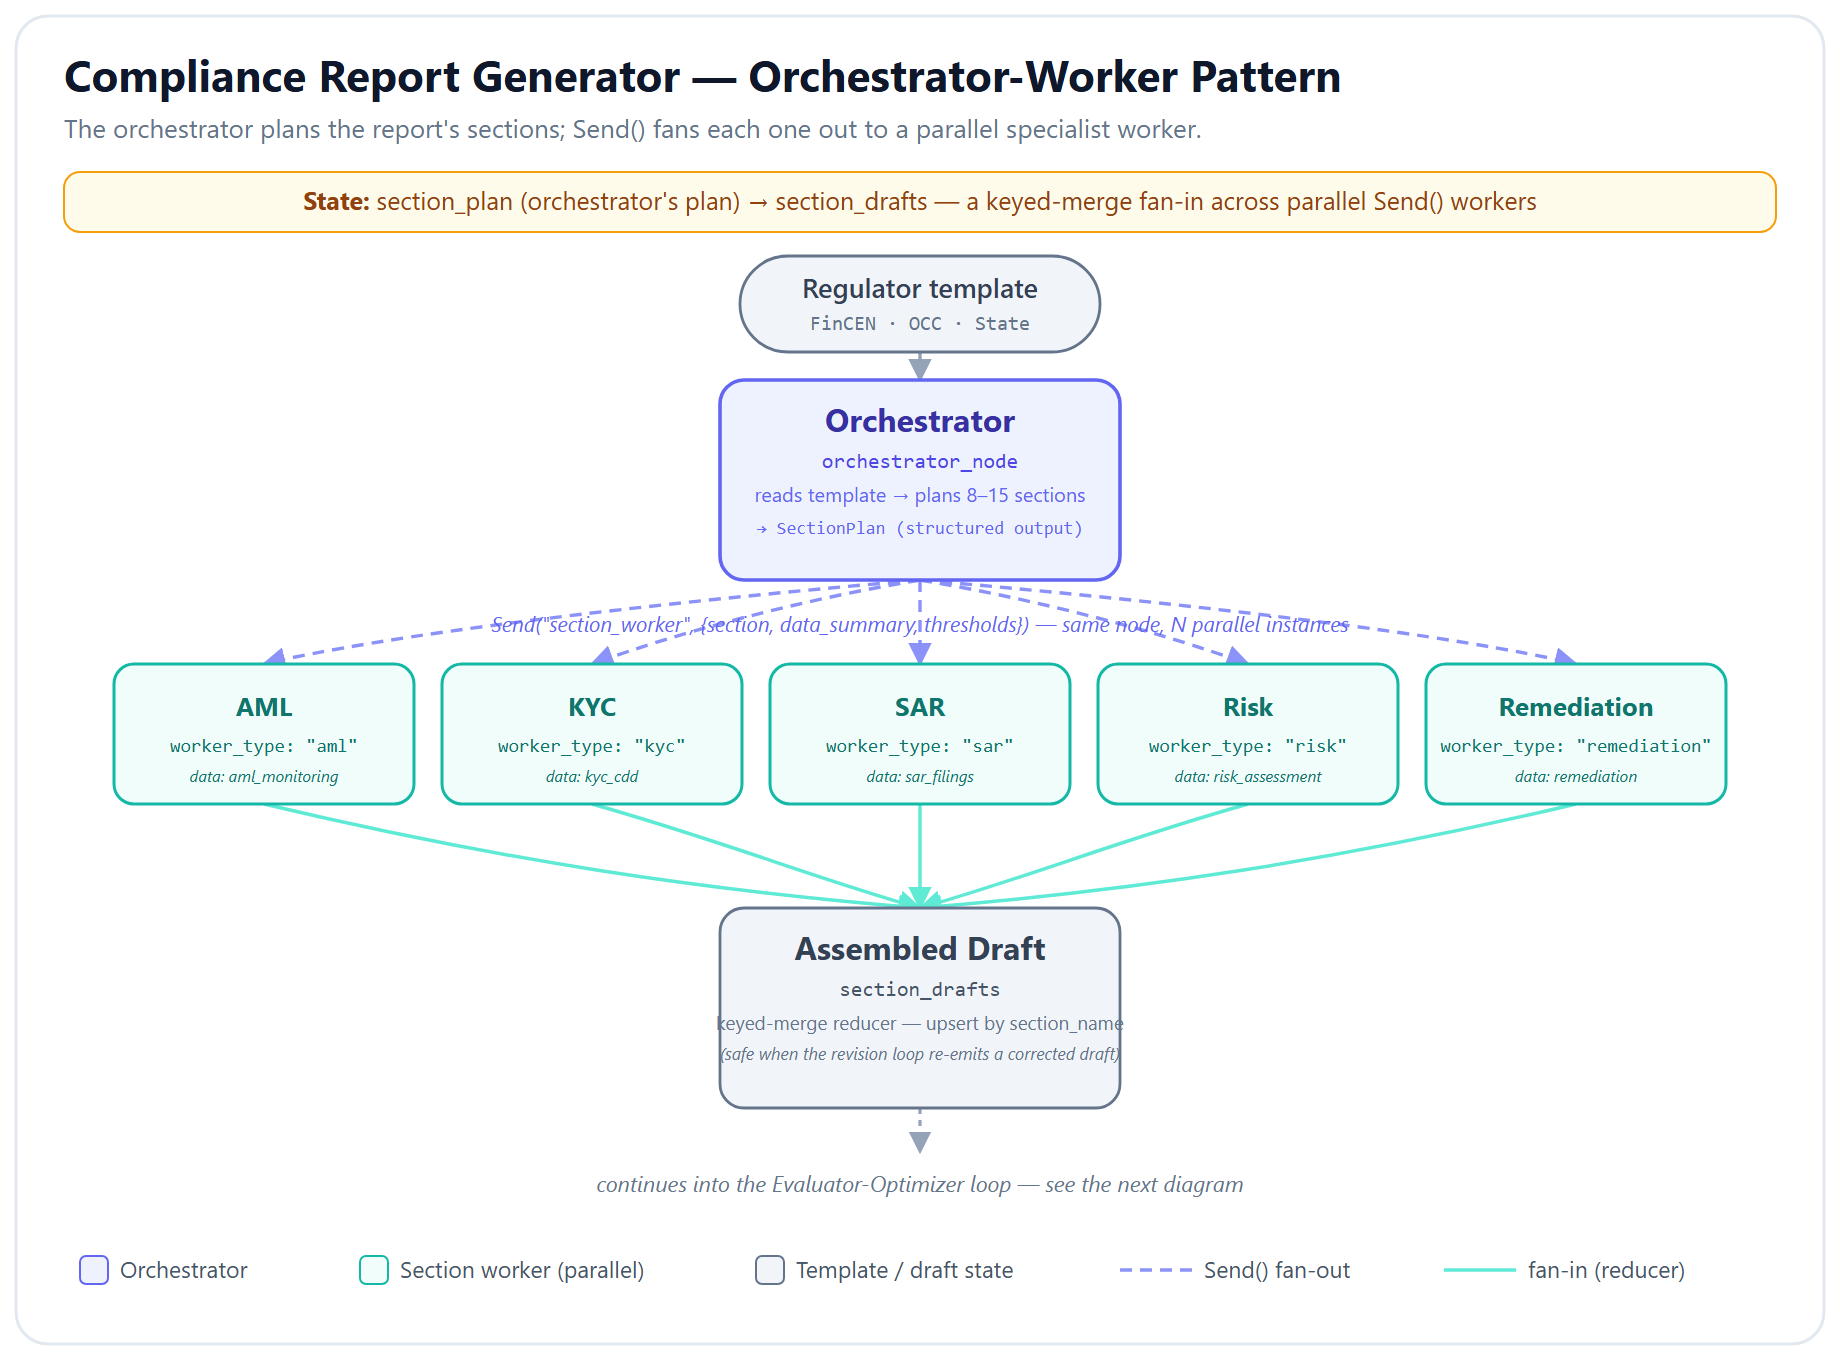

**Figure — Orchestrator-worker fan-out.** The orchestrator never writes a section itself — it plans the work and lets `Send()` dispatch parallel `section_worker` instances, whose drafts merge back into `section_drafts` by section name.

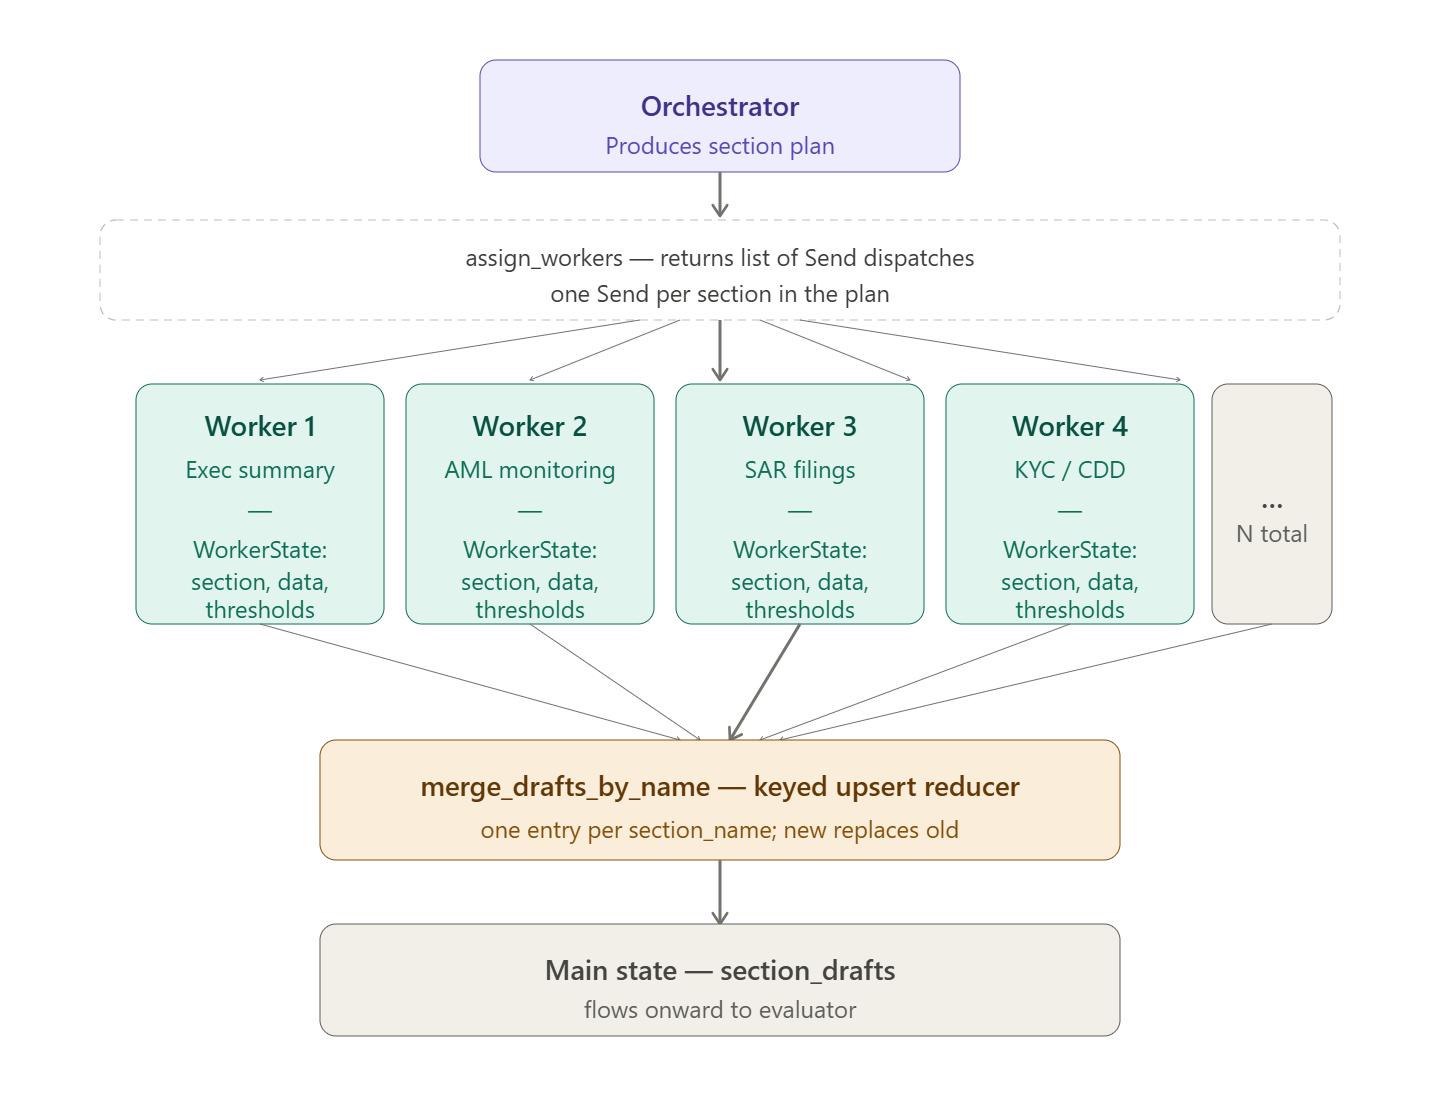

**Figure — Fan-out and fan-in.** `assign_workers` returns one `Send` per planned section; each worker gets its own `WorkerState`, and `merge_drafts_by_name` merges the drafts back into `section_drafts` — one entry per section, a newer draft replacing an older one.

In [12]:
def orchestrator_node(state: ComplianceReportState) -> dict:
    """Orchestrator: reads the template and creates a section-by-section work plan.

    DESIGN NOTES:
    1. A single-granularity rule: without it, the planner can produce 32 sections
       for a ~10-section template by planning parent + subsections as
       independent workers.
    2. Also EXCLUDES "Executive Summary" / "Management Summary" from the plan.
       If the orchestrator drafted one AND the synthesizer generated one, the
       report would carry a duplicate at the top. The synthesizer owns the exec
       summary exclusively.
    """
    print(f"\n{'='*60}")
    print(f"ORCHESTRATOR: Planning {state['regulator']} report for {state['quarter']}")
    print(f"{'='*60}")

    template = state["template"]
    regulator = state["regulator"]
    quarter = state["quarter"]
    available_data = list(DATA_SUMMARY.keys())

    messages = [
        SystemMessage(content="""You are a banking compliance report planner. Your job is to read a
regulatory report template and create a detailed work plan that assigns each section to a specialist worker.

WORKER TYPES and their specializations:
- "aml": Anti-Money Laundering transaction monitoring, alerts, CTR filings, system performance
- "kyc": Know Your Customer, Customer Due Diligence (CDD), Enhanced Due Diligence (EDD), beneficial ownership
- "sar": Suspicious Activity Reporting, SAR filings, timeliness, narrative quality
- "risk": Risk assessment, risk ratings, high-risk customer monitoring, enterprise risk
- "remediation": Prior findings, corrective actions, overdue items, audit results

RULES:
1. Every data-bearing section in the template MUST be assigned to exactly one worker.
2. Sections that are purely structural (title page, certification, appendices) should be EXCLUDED.
3. Each assignment must include the primary regulatory citation.
4. Map data_sources to the categories available in our DATA_SUMMARY.

*** CRITICAL GRANULARITY RULE ***
5. Pick ONE level of decomposition per topic --- either the PARENT section OR its subsections, NEVER BOTH.
6. Target 8-15 total sections for a typical quarterly template.

*** CRITICAL EXCLUSION RULE (new) ***
7. DO NOT include the Executive Summary or Management Summary as a worker assignment.
   The synthesizer generates the executive summary after all sections are complete,
   using the assembled content plus DATA_SUMMARY. Listing it as a worker section
   creates a duplicate at the top of the final report.
   If the template has a section titled "Executive Summary", "Management Summary",
   or similar, SKIP it in your plan.
"""),
        HumanMessage(content=f"""Create a section plan for the {regulator} quarterly compliance report
for {quarter}.

TEMPLATE:
{template}

AVAILABLE DATA CATEGORIES: {available_data}

Return a SectionPlan with all data-bearing sections assigned to workers.
Remember: ONE level of granularity per topic. SKIP any executive/management summary section.
Target 8-15 sections total.""")
    ]

    structured_llm = llm_orchestrator.with_structured_output(SectionPlan)
    plan = structured_llm.invoke(messages)

    # Defensive filter: drop any executive/management summary the LLM still included.
    SUMMARY_NAMES = ("executive summary", "management summary")
    filtered = [section for section in plan.sections
                if not any(summary_name in section.section_name.lower()
                           for summary_name in SUMMARY_NAMES)]
    if len(filtered) < len(plan.sections):
        dropped = [section.section_name for section in plan.sections
                   if section not in filtered]
        print(f"  (Filtered out summary sections from plan: {dropped})")

    print(f"\nPlanned {len(filtered)} sections:")
    for position, section in enumerate(filtered, 1):
        print(f"  {position}. [{section.worker_type.upper()}] {section.section_name}")
        print(f"     Data: {section.data_sources} | Ref: {section.regulatory_reference}")

    return {
        "section_plan": [section.model_dump() for section in filtered],
    }


print("Orchestrator node defined (excludes exec/management summary from plan).")


Orchestrator node defined (excludes exec/management summary from plan).


---

## Section 10: Fan-Out with the Send API

This is the **most important pattern** in this lab. The `Send` API creates **independent, parallel worker instances** --- one for each section in the orchestrator's plan.

### How `Send` Works

```python
Send("node_name", state_for_that_node)
```

- `"node_name"` is the target node (our `section_worker`)
- `state_for_that_node` is a **fresh `WorkerState`** with just that section's assignment
- LangGraph creates N parallel instances of `section_worker`, one per `Send`
- All N workers run concurrently and their outputs merge via the `merge_drafts_by_name` reducer

### Fan-Out / Fan-In Flow

```
Orchestrator plans 5 sections
    |
    +-- Send("section_worker", {section: AML_section, ...})
    +-- Send("section_worker", {section: KYC_section, ...})
    +-- Send("section_worker", {section: SAR_section, ...})      All run in PARALLEL
    +-- Send("section_worker", {section: Risk_section, ...})
    +-- Send("section_worker", {section: Remediation_section, ...})
    |
    v
section_drafts = [draft_AML, draft_KYC, draft_SAR, draft_Risk, draft_Remediation]  <-- Reducer merges
```

In [13]:
def assign_workers(state: ComplianceReportState) -> list[Send]:
    """Fan-out function: creates a parallel Send() for each planned section.

    This is a CONDITIONAL EDGE function. Instead of returning a string
    (like a normal conditional edge), it returns a list of Send objects.
    LangGraph treats each Send as an independent worker invocation.
    """
    sends = []
    for section in state["section_plan"]:
        sends.append(
            Send("section_worker", {
                "section": section,
                "data_summary": DATA_SUMMARY,
                "thresholds": thresholds,
            })
        )

    print(f"\nFAN-OUT: Dispatching {len(sends)} parallel workers...")
    for send_command in sends:
        print(f"  -> Worker for: {send_command.arg['section']['section_name']} "
              f"[{send_command.arg['section']['worker_type']}]")

    return sends


print("Fan-out function defined.")

Fan-out function defined.


---

## Section 11: Section Worker Node

A **universal worker** that handles all 5 specialist types (AML, KYC, SAR, Risk, Remediation). Rather than writing 5 separate worker functions, we use a single worker that adapts its behavior based on the `worker_type` field in its assignment.

Each worker:
1. Reads its section assignment from `WorkerState`
2. Pulls the relevant subset of `DATA_SUMMARY` based on `data_sources`
3. Crafts a detailed prompt with the actual numbers
4. Uses `gpt-4.1-mini` (temp=0.2) to draft the section narrative
5. Returns `{"section_drafts": [draft]}` which the reducer merges into the main state

In [14]:
# Worker-type-specific system prompts
WORKER_PROMPTS = {
    "aml": """You are an AML (Anti-Money Laundering) compliance report writer for a mid-size U.S. bank.
Your expertise covers BSA transaction monitoring systems, alert management, Currency Transaction Reports (CTRs),
and AML program effectiveness. Use precise regulatory terminology per 31 CFR Part 1020.
Always cite exact numbers from the provided data. Never invent statistics.""",

    "kyc": """You are a KYC/CDD (Know Your Customer / Customer Due Diligence) compliance report writer.
Your expertise covers customer identification programs (CIP), KYC verification, beneficial ownership
requirements (31 CFR 1010.230), Enhanced Due Diligence (EDD) for high-risk customers, and PEP screening.
Always cite exact numbers from the provided data. Never invent statistics.""",

    "sar": """You are a SAR (Suspicious Activity Report) compliance report writer.
Your expertise covers SAR filing requirements (31 CFR 1020.320), suspicious activity detection,
SAR timeliness requirements (30-day initial, 60-day maximum), narrative quality standards,
and FinCEN filing procedures. Always cite exact numbers from the provided data.""",

    "risk": """You are a risk assessment compliance report writer.
Your expertise covers customer risk ratings, geographic risk factors, product risk assessments,
enterprise risk management, and BSA/AML risk assessment methodology.
Always cite exact numbers from the provided data. Never invent statistics.""",

    "remediation": """You are a regulatory findings remediation report writer.
Your expertise covers corrective action plans, Matters Requiring Attention (MRAs),
audit findings, remediation tracking, and regulatory examination response.
Always cite exact numbers from the provided data. Highlight overdue items clearly.""",
}


def section_worker(state: WorkerState) -> dict:
    """Universal section worker: drafts one section of the compliance report.

    DESIGN NOTE: When the prompt does not explicitly require them, a model can
    return an empty `key_metrics` dictionary, so the prompt below mandates
    populating key_metrics with every numeric value
    cited in the narrative, as a flat {metric_name: numeric_value} dict. The
    downstream evaluator can then cross-check these keys against DATA_SUMMARY.
    """
    section = state["section"]
    section_name = section["section_name"]
    worker_type = section["worker_type"]
    data_sources = section["data_sources"]
    description = section["description"]
    regulatory_reference = section["regulatory_reference"]

    print(f"  WORKER [{worker_type.upper()}]: Drafting '{section_name}'...")

    relevant_data = {}
    for source in data_sources:
        if source in state["data_summary"]:
            relevant_data[source] = state["data_summary"][source]

    relevant_thresholds = state["thresholds"]
    system_prompt = WORKER_PROMPTS.get(worker_type, WORKER_PROMPTS["aml"])

    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=f"""Draft the following section for a quarterly compliance report.

SECTION: {section_name}
DESCRIPTION: {spell_out_section_signs(description)}
REGULATORY REFERENCE: {spell_out_section_signs(regulatory_reference)}

DATA (use these EXACT numbers --- do not invent or approximate):
{json.dumps(relevant_data, indent=2)}

REGULATORY THRESHOLDS:
{json.dumps(relevant_thresholds, indent=2)}

INSTRUCTIONS:
1. Write a professional regulatory narrative for this section.
2. Include ALL relevant statistics from the data provided.
3. Use proper regulatory terminology (BSA, AML, SAR, CTR, KYC, CDD, EDD, PEP as appropriate).
4. Format with markdown headers, bullet points, and tables where the template requires them.
5. Cite the regulatory reference where appropriate.
6. Do NOT include any customer names or IDs --- only aggregated statistics.

*** MANDATORY: POPULATE key_metrics ***
7. For EVERY numeric value cited in your narrative, add it to key_metrics as
   {{metric_name: numeric_value}}. Examples:
     "total_transactions": 50000
     "total_transaction_amount_usd": 311260070.15
     "suspicious_transactions_count": 1053
     "suspicious_transactions_pct": 2.11
     "sar_count": 250
     "ctr_eligible_count": 4347
     "kyc_verified_pct": 32.66
   This enables downstream automated verification. An empty key_metrics dict
   is NOT acceptable --- your draft will fail evaluation.

Return a SectionDraft with the narrative content AND a fully populated key_metrics dict.""")
    ]

    structured_llm = llm_worker.with_structured_output(SectionDraft, method="function_calling",
                                                       include_raw=True)
    draft = invoke_structured_with_retry(structured_llm, messages)
    if draft is None:
        raise RuntimeError(f"No usable draft for {section_name!r} after 3 attempts (printed above).")

    draft.content = redact_pii(draft.content)

    metric_count = len(draft.key_metrics) if draft.key_metrics else 0
    print(f"  WORKER [{worker_type.upper()}]: Completed '{section_name}' "
          f"({len(draft.content)} chars, {metric_count} metrics, confidence={draft.confidence:.2f})")

    return {"section_drafts": [draft.model_dump()]}


print("Section worker node defined (requires populated key_metrics).")
print(f"Worker types available: {list(WORKER_PROMPTS.keys())}")


Section worker node defined (requires populated key_metrics).
Worker types available: ['aml', 'kyc', 'sar', 'risk', 'remediation']


---

## Section 12: Evaluator Node --- 3-Check Validation

The evaluator implements the **Evaluator-Optimizer pattern (Pattern #5)**. It performs three independent checks on each section draft:

| Check | What It Validates | Why It Matters |
|-------|-------------------|----------------|
| **Numerical Accuracy** | Every number matches `DATA_SUMMARY` | Q2 2024's numerical error triggered a regulatory inquiry |
| **Terminology Compliance** | Correct use of BSA/AML terms | Regulators penalize sloppy terminology |
| **Cross-Reference Integrity** | References between sections are consistent | "Section 2 references 250 SARs" must match Section 2's actual number |

If ANY check fails, the evaluator provides **specific feedback** that tells the revision node exactly what to fix. This is the key to the evaluator-optimizer loop working --- vague feedback like "improve quality" would not help.

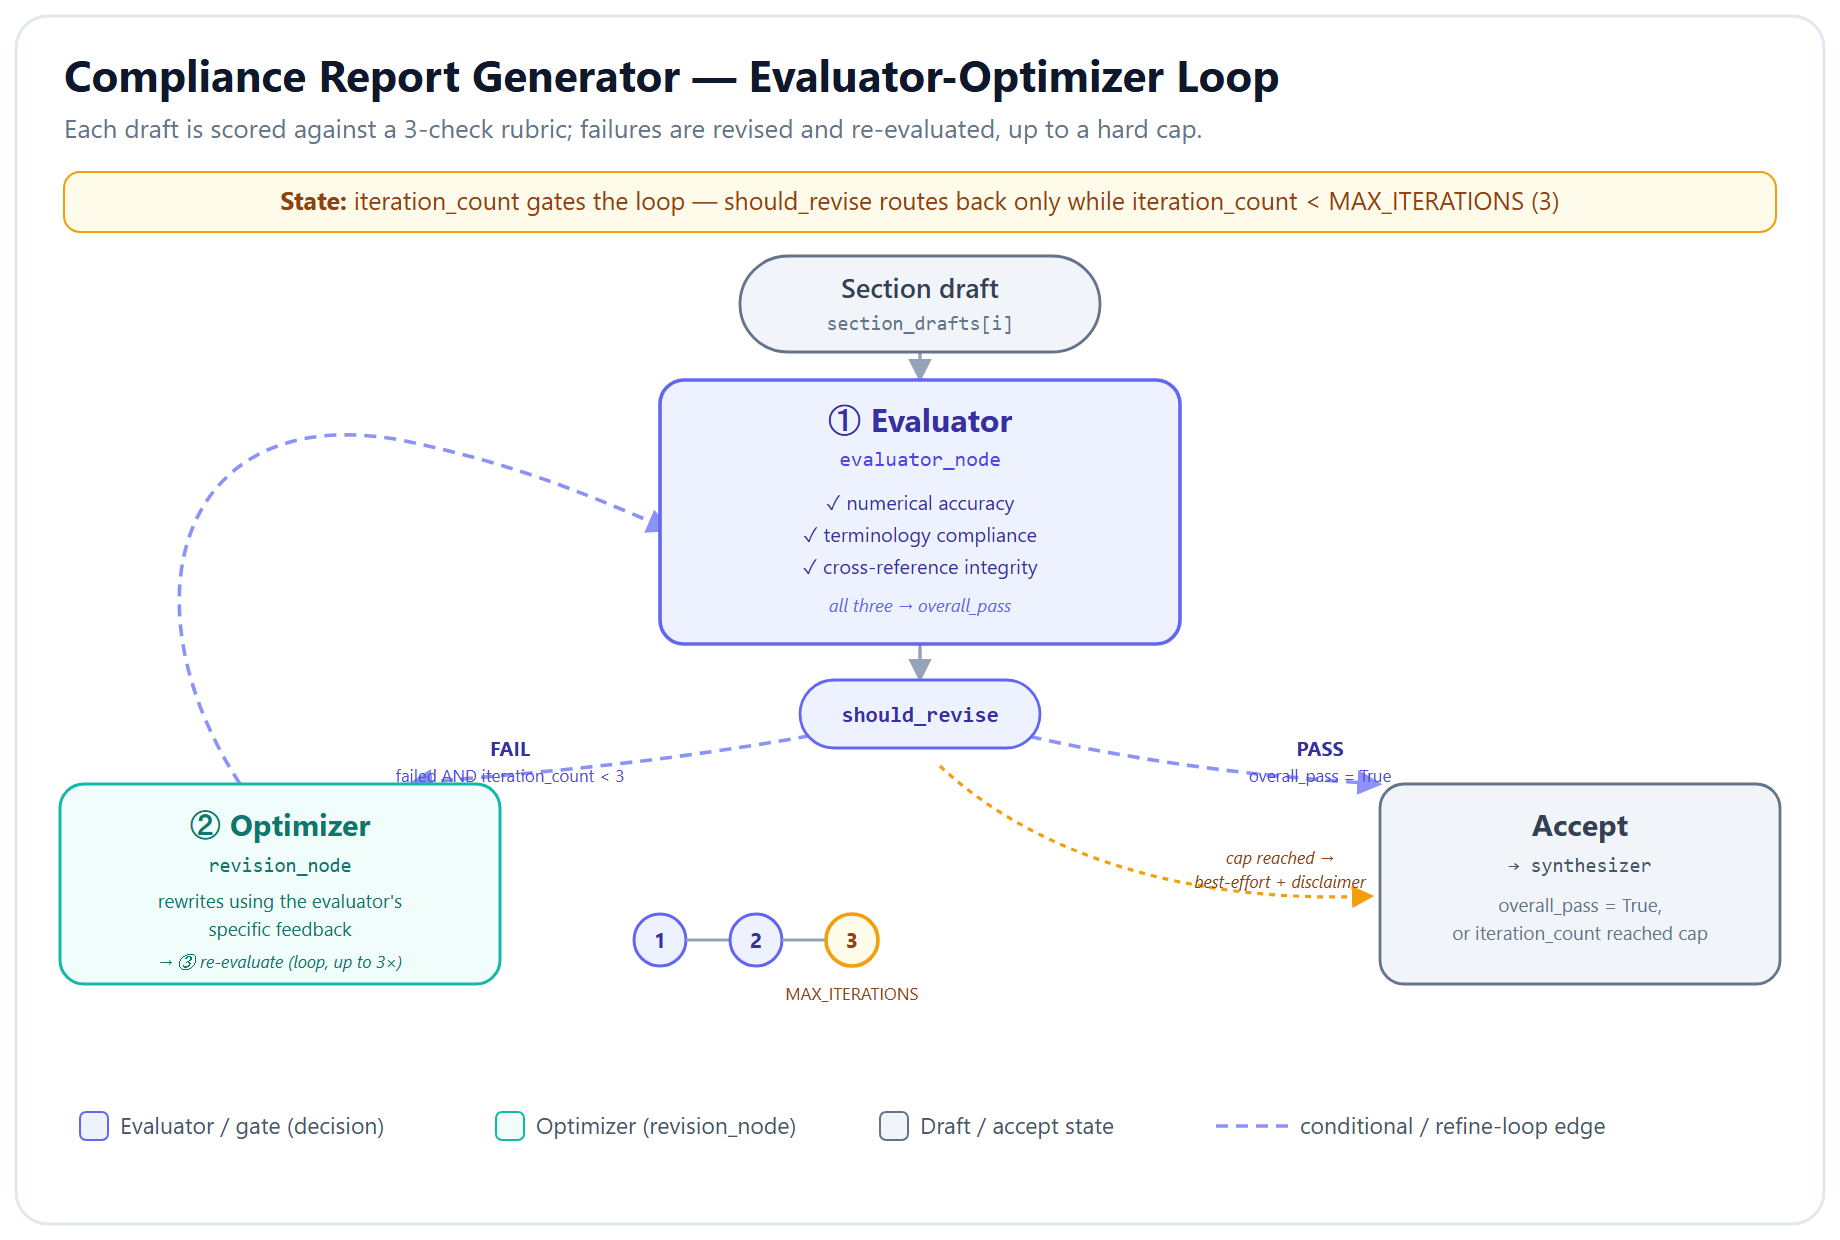

**Figure — Evaluator-optimizer loop.** A failing draft doesn't get infinite retries — `should_revise` loops it through the optimizer only while `iteration_count` is under the cap, then proceeds anyway with a disclaimer.

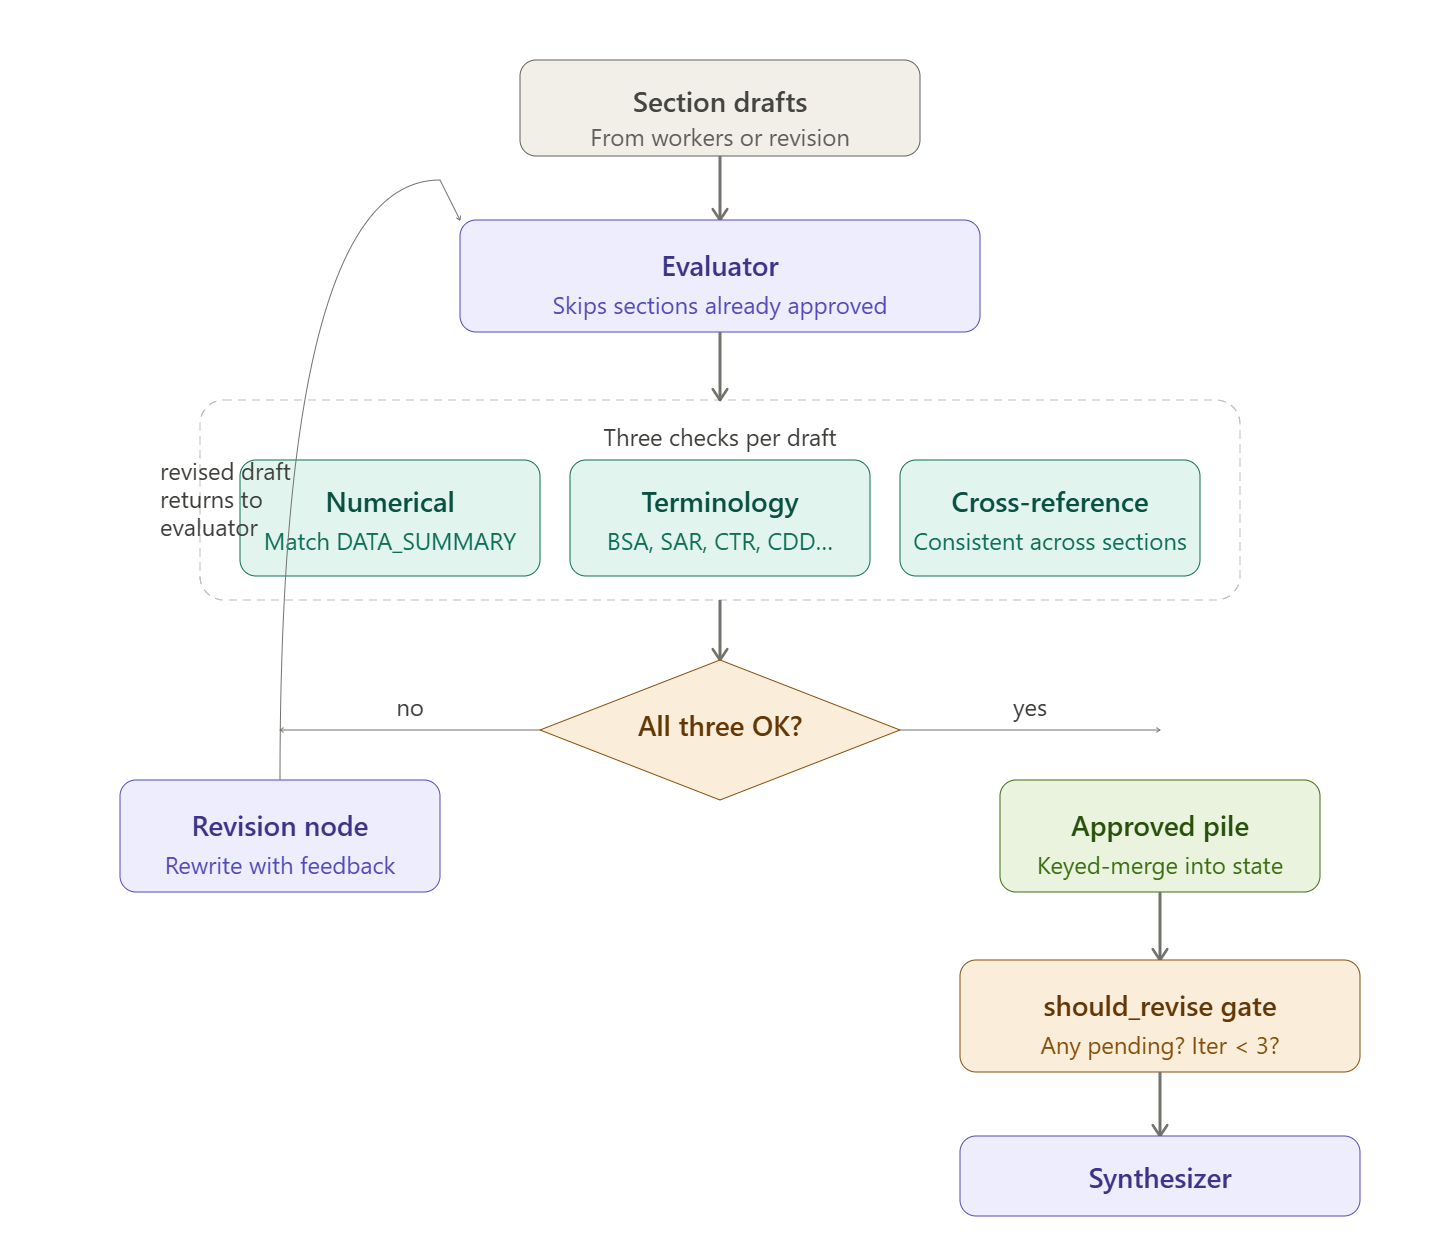

**Figure — Inside the evaluator-optimizer loop.** Every draft gets three checks. A failing draft goes to the revision node and back to the evaluator; passing drafts are keyed-merged into the approved pile. The `should_revise` gate stops the loop once nothing is pending or the iteration cap (`MAX_ITERATIONS = 3`) is reached.

In [15]:
def evaluator_node(state: ComplianceReportState) -> dict:
    """Evaluator: validates each section draft against 3 quality checks.

    DESIGN NOTES:
    1. Skips sections already in `approved_sections`.
    2. Uses an idempotent rubric that explicitly forbids re-grading stylistic nits.
    3. Evaluates all pending drafts IN PARALLEL via ThreadPoolExecutor.
       Evaluated sequentially, this node is the latency bottleneck --- one FinCEN
       run spent 7+ minutes in iteration 1 checking 9 drafts one by one.
       Parallel evaluation brings that down by roughly the degree of concurrency.
    """
    from concurrent.futures import ThreadPoolExecutor, as_completed

    already_approved_names = {
        draft["section_name"] for draft in state.get("approved_sections", [])
    }
    drafts_to_evaluate = [
        draft for draft in state["section_drafts"]
        if draft["section_name"] not in already_approved_names
    ]

    print(f"\n{'='*60}")
    print(f"EVALUATOR: Checking {len(drafts_to_evaluate)} section drafts "
          f"(skipping {len(already_approved_names)} already approved)")
    print(f"Iteration: {state.get('iteration_count', 0) + 1}")
    print(f"{'='*60}")

    evaluation_system_prompt = """You are a regulatory compliance quality evaluator for banking reports.
Evaluate the given section draft against THREE checks:

1. NUMERICAL ACCURACY: Verify that every number in the narrative matches the provided DATA_SUMMARY.
   Flag only numbers that are WRONG or INVENTED. Do NOT flag acceptable rounding
   (e.g., 32.66% rendered as 32.7% or 33%) --- that is stylistic, not an accuracy error.
   Regulatory thresholds quoted from statute (CTR $10,000; SAR $5,000 monetary threshold;
   SAR 30/60-day timeliness) are allowed even if not in DATA_SUMMARY --- these are statutory facts.

2. TERMINOLOGY COMPLIANCE: Check that regulatory terms are used correctly:
   - BSA (Bank Secrecy Act) vs AML (Anti-Money Laundering) --- related but distinct
   - SAR (Suspicious Activity Report) --- not "suspicious report"
   - CTR (Currency Transaction Report) --- for transactions over $10,000
   - KYC (Know Your Customer) vs CDD (Customer Due Diligence)
   - EDD (Enhanced Due Diligence) --- for high-risk customers only
   - PEP (Politically Exposed Person)
   Only flag USAGE errors (wrong term for the concept), not stylistic preferences.

3. CROSS-REFERENCE INTEGRITY: If the section references numbers that should match
   DATA_SUMMARY or other sections, verify consistency.

IDEMPOTENCY RULE:
- If a section is factually accurate and uses correct terminology, PASS IT.
- Do NOT invent new nits to justify a FAIL verdict.
- Your job is correctness gating, not copy-editing.

Provide SPECIFIC feedback ONLY for real failures. If everything is fine, pass the section."""

    def evaluate_one(draft: dict) -> tuple[dict, dict]:
        """Evaluate a single draft; returns (draft, evaluation_result_dict)."""
        messages = [
            SystemMessage(content=evaluation_system_prompt),
            HumanMessage(content=f"""Evaluate this section draft:

SECTION: {draft['section_name']}
CONTENT:
{draft['content']}

KEY METRICS CLAIMED BY WORKER:
{json.dumps(draft['key_metrics'], indent=2)}

GROUND TRUTH DATA:
{json.dumps(DATA_SUMMARY, indent=2)}

Return an EvaluationResult with your assessment.""")
        ]
        structured_llm = llm_evaluator.with_structured_output(EvaluationResult)
        result = structured_llm.invoke(messages)
        return draft, result.model_dump()

    # Fan out evaluations in parallel. 5 workers is a sensible default for API calls.
    evaluation_results = []
    sections_needing_revision = []
    approved = []
    results_by_name = {}

    if drafts_to_evaluate:
        with ThreadPoolExecutor(max_workers=5) as thread_pool:
            futures = {thread_pool.submit(evaluate_one, draft): draft
                       for draft in drafts_to_evaluate}
            for future in as_completed(futures):
                draft, result = future.result()
                results_by_name[draft["section_name"]] = (draft, result)

    # Process results in the original order so logs read predictably.
    for draft in drafts_to_evaluate:
        section_name = draft["section_name"]
        _, result = results_by_name[section_name]
        evaluation_results.append(result)

        status = "PASS" if result["overall_pass"] else "FAIL"
        checks = [
            f"Numerical={'OK' if result['numerical_accuracy'] else 'FAIL'}",
            f"Terminology={'OK' if result['terminology_compliance'] else 'FAIL'}",
            f"CrossRef={'OK' if result['cross_reference_integrity'] else 'FAIL'}",
        ]
        print(f"  Evaluating: {section_name}...")
        print(f"    [{status}] {' | '.join(checks)}")

        if result["overall_pass"]:
            approved.append(draft)
        else:
            sections_needing_revision.append({
                "draft": draft,
                "feedback": result["feedback"],
            })
            print(f"    Feedback: {result['feedback'][:120]}...")

    passed = len(approved)
    failed = len(sections_needing_revision)
    print(f"\n  EVALUATOR SUMMARY: {passed} newly passed, {failed} need revision, "
          f"{len(already_approved_names)} carried over as approved")

    return {
        "evaluation_results": evaluation_results,
        "sections_needing_revision": sections_needing_revision,
        "approved_sections": approved,
        "iteration_count": state.get("iteration_count", 0) + 1,
    }


print("Evaluator node defined (parallel LLM calls, idempotent rubric).")


Evaluator node defined (parallel LLM calls, idempotent rubric).


---

## Section 13: Should-Revise Gate (Conditional Edge)

This conditional edge implements the **loop-back logic** of the evaluator-optimizer pattern:

```
If (any sections failed) AND (iteration_count < 3):
    -> Route to "revision" node (fix and re-evaluate)
Else:
    -> Route to "synthesizer" node (assemble final report)
```

The **maximum of 3 iterations** is a safety valve. In practice, most sections pass on the first or second attempt. The cap prevents infinite loops if the evaluator and worker have irreconcilable interpretations.

In [16]:
MAX_ITERATIONS = 3


def should_revise(state: ComplianceReportState) -> Literal["revision", "synthesizer"]:
    """Gate function: decides whether to loop back for revision or proceed to synthesis.

    Routes to 'revision' if there are failed sections AND we haven't exceeded
    the maximum iteration count. Otherwise routes to 'synthesizer'.
    """
    failed = state.get("sections_needing_revision", [])
    iteration = state.get("iteration_count", 0)

    if failed and iteration < MAX_ITERATIONS:
        print(f"\n  GATE: {len(failed)} sections need revision (iteration {iteration}/{MAX_ITERATIONS})")
        print(f"        -> Routing to REVISION")
        return "revision"
    else:
        if failed:
            print(f"\n  GATE: {len(failed)} sections still failing but max iterations ({MAX_ITERATIONS}) reached")
            print(f"        -> Proceeding to SYNTHESIZER with best-effort drafts")
        else:
            print(f"\n  GATE: All sections passed evaluation!")
            print(f"        -> Routing to SYNTHESIZER")
        return "synthesizer"


print(f"Should-revise gate defined (max iterations = {MAX_ITERATIONS}).")

Should-revise gate defined (max iterations = 3).


---

## Section 14: Revision Node

When a section fails evaluation, the revision node takes the original draft **plus the evaluator's specific feedback** and asks the worker LLM to fix the identified issues.

This is what makes the evaluator-optimizer loop effective: the feedback is **actionable and specific**, not generic. For example:
- "The SAR count states 248 but DATA_SUMMARY shows 250"
- "Section uses 'KYC' where 'CDD' is the correct regulatory term per 31 CFR 1010.230"
- "Cross-reference to Section 1 claims 45,000 transactions but the AML section reports 50,000"

In [17]:
def revision_node(state: ComplianceReportState) -> dict:
    """Revision node: fixes failed sections based on evaluator feedback.

    DESIGN NOTES:
    1. Parallelized with ThreadPoolExecutor (run sequentially, it is the second bottleneck).
    2. Strict prompt: the revision model is explicitly told to use ONLY
       numbers present in DATA_SUMMARY and to preserve parts that were already
       correct. Without that, a revision can introduce new invented numbers
       while fixing other issues (as Part VI of an OCC run did in iteration 3).
    """
    from concurrent.futures import ThreadPoolExecutor, as_completed

    print(f"\n{'='*60}")
    print(f"REVISION: Fixing {len(state['sections_needing_revision'])} sections")
    print(f"{'='*60}")

    revision_system_prompt = """You are a compliance report editor. Your task is to revise a section
draft based on specific evaluator feedback.

HARD RULES (violating these is worse than not revising):
1. Fix ONLY the specific issues listed in the evaluator feedback. Do not touch
   parts of the draft that were not flagged.
2. Every numeric value in your revised draft MUST be present in DATA_SUMMARY
   (or be a documented statutory threshold like CTR $10,000, SAR $5,000).
   If the evaluator asks you to add detail you cannot source from DATA_SUMMARY,
   omit that detail rather than invent numbers.
3. Preserve the original markdown structure, headers, tables, and regulatory citations
   unless the feedback specifically asks you to change them.
4. Populate key_metrics with every number cited, as flat {metric_name: value} pairs."""

    def revise_one(revision_item: dict) -> dict:
        """Revise a single failed section; returns the revised draft dict."""
        draft = revision_item["draft"]
        feedback = revision_item["feedback"]
        section_name = draft["section_name"]

        messages = [
            SystemMessage(content=revision_system_prompt),
            HumanMessage(content=f"""Revise this section draft based on the evaluator's feedback.

SECTION: {section_name}

ORIGINAL DRAFT:
{spell_out_section_signs(draft['content'])}

EVALUATOR FEEDBACK (fix these specific issues, nothing else):
{spell_out_section_signs(feedback)}

GROUND TRUTH DATA (use ONLY these numbers):
{json.dumps(DATA_SUMMARY, indent=2)}

Return a revised SectionDraft that addresses every feedback item while keeping
the rest of the draft unchanged. Populate key_metrics with all cited numbers.""")
        ]

        structured_llm = llm_worker.with_structured_output(SectionDraft, method="function_calling",
                                                           include_raw=True)
        revised = invoke_structured_with_retry(structured_llm, messages)
        if revised is None:
            # No usable revision: keep the previous draft, and the evaluator judges it again.
            print(f"  Revision of {section_name!r} failed — keeping the previous draft.")
            return draft
        revised.content = redact_pii(revised.content)
        return revised.model_dump()

    revised_drafts = []
    revised_by_name = {}

    if state["sections_needing_revision"]:
        with ThreadPoolExecutor(max_workers=5) as thread_pool:
            futures = {
                thread_pool.submit(revise_one, revision_item): revision_item["draft"]["section_name"]
                for revision_item in state["sections_needing_revision"]
            }
            for future in as_completed(futures):
                section_name = futures[future]
                revised_by_name[section_name] = future.result()

    # Emit logs in input order for readability
    for revision_item in state["sections_needing_revision"]:
        section_name = revision_item["draft"]["section_name"]
        revised = revised_by_name[section_name]
        revised_drafts.append(revised)
        print(f"  Revising: {section_name}")
        print(f"  Feedback: {revision_item['feedback'][:100]}...")
        print(f"  Revised: {section_name} ({len(revised['content'])} chars, "
              f"{len(revised.get('key_metrics', {}))} metrics)")

    return {
        "section_drafts": revised_drafts,
        "sections_needing_revision": [],
    }


print("Revision node defined (parallel LLM calls, strict number discipline).")


Revision node defined (parallel LLM calls, strict number discipline).


---

## Section 15: Synthesis Node

Once all sections pass evaluation (or max iterations are reached), the synthesizer:

1. **Assembles** all approved section drafts into a single coherent report
2. **Generates** an executive summary using `gpt-4.1-mini` (temp=0.3) that highlights key findings
3. **Formats** the complete report with proper section numbering and regulatory headers

In [18]:
def synthesis_node(state: ComplianceReportState) -> dict:
    """Synthesizer: assembles all approved sections into a full report
    and generates an executive summary.

    DESIGN NOTE: No silent dedup here --- it would only paper over a
    state-accumulation bug. With the custom reducer in place, both
    `section_drafts` and `approved_sections` already contain one entry per
    section_name. Synthesis prefers the approved version; if a section hit
    the iteration cap and was never approved, its best-effort draft is used
    as fallback, and we log a warning so the compliance officer can see it.
    """
    print(f"\n{'='*60}")
    print(f"SYNTHESIZER: Assembling {state['regulator']} report for {state['quarter']}")
    print(f"{'='*60}")

    # Start with all drafts (fallback layer); overlay approved on top (preferred)
    by_name = {draft["section_name"]: {"section": draft, "approved": False}
               for draft in state.get("section_drafts", [])}
    for draft in state.get("approved_sections", []):
        by_name[draft["section_name"]] = {"section": draft, "approved": True}

    unique_sections = [entry["section"] for entry in by_name.values()]
    unapproved = [section_name for section_name, entry in by_name.items()
                  if not entry["approved"]]

    print(f"  Total unique sections: {len(unique_sections)}")
    print(f"  Approved:              {len(unique_sections) - len(unapproved)}")
    if unapproved:
        print(f"  WARNING -- hit iteration cap without approval: {unapproved}")

    report_body = ""
    for section in unique_sections:
        report_body += f"\n\n{section['content']}\n"

    messages = [
        SystemMessage(content="""You are a senior compliance officer writing an executive summary
for a quarterly regulatory report. The summary should be concise (250-400 words),
highlight key metrics, flag any areas of concern (especially overdue remediations
or elevated risk indicators), and conclude with a forward-looking compliance posture assessment.
Use professional regulatory language."""),
        HumanMessage(content=f"""Write an executive summary for the {state['regulator']} quarterly
compliance report for {state['quarter']}.

KEY DATA:
{json.dumps(DATA_SUMMARY, indent=2)}

SECTIONS INCLUDED:
{[section['section_name'] for section in unique_sections]}

Write a professional executive summary.""")
    ]

    summary_response = llm_synthesis.invoke(messages)
    executive_summary = summary_response.content

    full_report = f"""# {state['regulator']} Quarterly Compliance Report
## {state['quarter']} | MidwestBank
## Prepared: {datetime.now().strftime('%Y-%m-%d')}

---

## Executive Summary

{executive_summary}

---

{report_body}

---

## Certification

I certify that the information contained in this report is accurate and complete
to the best of my knowledge.

**Compliance Officer:** _______________________
**Date:** _______________________
"""

    print(f"  Executive summary: {len(executive_summary)} chars")
    print(f"  Full report: {len(full_report)} chars")

    return {
        "executive_summary": executive_summary,
        "full_report": full_report,
    }


print("Synthesis node defined.")


Synthesis node defined.


---

## Section 16: HITL Node --- Compliance Officer Review

In regulated industries like banking, **no AI-generated report goes to a regulator without human review**. This is not optional --- it is a regulatory requirement.

The `interrupt()` function **pauses the graph execution** and surfaces the report to a compliance officer. The graph remains suspended (checkpointed in memory) until the officer provides their review via `Command(resume=...)`.

### What the Officer Sees

The interrupt payload includes:
- The target regulator and reporting period
- The executive summary (so the officer does not need to read the full report to decide)
- The number of sections included
- A prompt requesting approval or revision notes

### What the Officer Returns

```python
Command(resume={"approved": True, "notes": "Approved. Minor formatting note: ..."})  # Approve
Command(resume={"approved": False, "notes": "SAR section needs additional context on..."})  # Reject
```

In [19]:
def compliance_officer_review(state: ComplianceReportState) -> dict:
    """HITL node: pauses execution for compliance officer review.

    DESIGN NOTE: If any sections hit the iteration cap without approval, a
    warning printed during synthesis is not enough --- the officer could
    approve the report without acknowledging them. So:
    - Unresolved sections are surfaced PROMINENTLY in the HITL payload.
    - The resume Command accepts an optional `acknowledged_warnings` list.
    - If there are unresolved sections and the officer does not acknowledge
      them, we record that fact in state so the final_report_node can prepend
      a visible disclaimer to the submission.
    """
    print(f"\n{'='*60}")
    print(f"HITL: Awaiting compliance officer review...")
    print(f"{'='*60}")

    approved_names = {draft["section_name"] for draft in state.get("approved_sections", [])}
    all_drafts = state.get("section_drafts", []) + state.get("approved_sections", [])
    seen_names, unique_drafts = set(), []
    for draft in all_drafts:
        if draft["section_name"] not in seen_names:
            seen_names.add(draft["section_name"])
            unique_drafts.append(draft)

    unresolved = [
        draft["section_name"] for draft in unique_drafts
        if draft["section_name"] not in approved_names
    ]

    review_payload = {
        "type": "compliance_review",
        "regulator": state["regulator"],
        "quarter": state["quarter"],
        "executive_summary": state["executive_summary"],
        "section_count": len(unique_drafts),
        "approved_count": len(approved_names),
        "unresolved_sections": unresolved,
        "iterations_used": state.get("iteration_count", 0),
        "report_length": len(state.get("full_report", "")),
        "message": (
            f"Please review the {state['regulator']} compliance report for {state['quarter']}. "
            f"{len(approved_names)} of {len(unique_drafts)} sections passed evaluation. "
            + (f"WARNING: {len(unresolved)} section(s) hit the iteration cap and were not fully validated: {unresolved}. "
               "Reply with approved=True/False, notes, and acknowledged_warnings=[...] listing any unresolved section names you accept.")
               if unresolved else
               "All sections passed evaluation. Reply with approved=True/False and any notes."
        ),
    }

    print(f"  Regulator: {state['regulator']}")
    print(f"  Quarter:   {state['quarter']}")
    print(f"  Sections:  {len(unique_drafts)} total, {len(approved_names)} approved, {len(unresolved)} unresolved")
    print(f"  Report:    {review_payload['report_length']:,} chars")
    if unresolved:
        print(f"\n  !! ATTENTION: UNRESOLVED SECTIONS (hit iteration cap)")
        for name in unresolved:
            print(f"     - {name}")
        print(f"  Officer must supply acknowledged_warnings=[...] to accept these for submission.")
    print(f"\n  >>> Graph PAUSED --- waiting for Command(resume=...) <<<")

    review = interrupt(review_payload)

    approved = review.get("approved", False)
    notes = review.get("notes", "")
    acknowledged_warnings = review.get("acknowledged_warnings", [])

    status = "APPROVED" if approved else "RETURNED FOR REVISION"
    print(f"\n  Officer decision: {status}")
    if notes:
        print(f"  Officer notes: {notes[:200]}")
    if unresolved:
        unacknowledged = [section_name for section_name in unresolved
                          if section_name not in acknowledged_warnings]
        if unacknowledged:
            print(f"  !! UNACKNOWLEDGED WARNINGS: {unacknowledged}")
            print(f"     These will be flagged prominently in the final report.")
        else:
            print(f"  Officer acknowledged all unresolved sections.")

    return {
        "hitl_approved": approved,
        "compliance_officer_notes": notes,
        "acknowledged_warnings": acknowledged_warnings,
        "unresolved_sections": unresolved,
    }


print("HITL compliance officer review node defined (surfaces unresolved sections).")


HITL compliance officer review node defined (surfaces unresolved sections).


---

## Section 17: Final Report Node

The final node incorporates the compliance officer's notes into the report and produces the submission-ready document.

In [20]:
def final_report_node(state: ComplianceReportState) -> dict:
    """Final report assembly: incorporates officer notes and produces the
    submission-ready document.

    DESIGN NOTE: If any sections hit the iteration cap AND were not explicitly
    acknowledged by the compliance officer, the final report prepends a
    visible disclaimer listing them. Acknowledged warnings are recorded in a
    less prominent review-notes section. This creates a durable audit trail of
    what was known at signing time.
    """
    print(f"\n{'='*60}")
    print(f"FINAL REPORT: Assembling submission-ready document")
    print(f"{'='*60}")

    notes = state.get("compliance_officer_notes", "")
    approved = state.get("hitl_approved", False)
    unresolved = state.get("unresolved_sections", []) or []
    acknowledged = state.get("acknowledged_warnings", []) or []
    unacknowledged = [section_name for section_name in unresolved
                      if section_name not in acknowledged]

    if not approved:
        final_report_text = f"""# REPORT NOT APPROVED

The {state['regulator']} report for {state['quarter']} was returned by the compliance officer.

**Officer Notes:** {notes}

**Action Required:** Address the officer's concerns and resubmit.
"""
        print(f"  Status: NOT APPROVED --- returned for revision")
        return {"final_report": final_report_text}

    # Build optional disclaimer banner for unacknowledged unresolved sections.
    disclaimer_banner = ""
    if unacknowledged:
        disclaimer_banner = f"""
> **!! COMPLIANCE WARNING --- UNACKNOWLEDGED UNRESOLVED SECTIONS**
>
> The following sections did not pass automated validation within the allowed
> number of revision iterations, and the compliance officer did not explicitly
> acknowledge them at sign-off time:
>
{chr(10).join(f'> - {section_name}' for section_name in unacknowledged)}
>
> Filing this report with these sections in their current state may create
> regulatory exposure. Review before submission.

---

"""

    # Officer acknowledgments (less prominent — recorded for audit trail)
    acknowledgment_section = ""
    if acknowledged:
        acknowledgment_section = f"""\n\n---\n\n## Officer Acknowledgments
The compliance officer acknowledged the following sections as reviewed
despite not passing full automated validation:
{chr(10).join(f'- {section_name}' for section_name in acknowledged)}
"""

    addendum = ""
    if notes:
        addendum = f"""\n\n---\n\n## Compliance Officer Review Notes

{notes}
"""

    final_report_text = (disclaimer_banner + state["full_report"]
                         + addendum + acknowledgment_section)
    final_report_text += f"\n\n**Report approved by compliance officer on {datetime.now().strftime('%Y-%m-%d %H:%M')}**\n"

    print(f"  Status: APPROVED")
    print(f"  Final report length: {len(final_report_text):,} chars")
    if unacknowledged:
        print(f"  !! Final report contains disclaimer banner for {len(unacknowledged)} unacknowledged section(s)")
    if acknowledged:
        print(f"  Officer acknowledged {len(acknowledged)} section(s) --- recorded in audit trail")

    return {"final_report": final_report_text}


print("Final report node defined (with disclaimer banner + audit trail).")


Final report node defined (with disclaimer banner + audit trail).


---

## Section 18: Build the Full LangGraph

Now we assemble all the nodes and edges into the complete state graph. The graph topology implements all four agentic patterns:

```
START
  |
  v
[orchestrator]  -----(conditional: assign_workers)-----> [section_worker] x N  (Send API fan-out)
                                                              |
                                                              v
                                                         [evaluator]
                                                              |
                                                    (conditional: should_revise)
                                                         /         \
                                                        v           v
                                                   [revision]   [synthesizer]
                                                        |           |
                                                        +--loop--+  v
                                                              [compliance_review]  (HITL interrupt)
                                                                    |
                                                                    v
                                                              [final_report]
                                                                    |
                                                                    v
                                                                   END
```

In [21]:
# =====================================================================
# BUILD THE STATE GRAPH
# =====================================================================

builder = StateGraph(ComplianceReportState)

# ---- Add all nodes ----
builder.add_node("orchestrator", orchestrator_node)
builder.add_node("section_worker", section_worker)          # Uses WorkerState internally
builder.add_node("evaluator", evaluator_node)
builder.add_node("revision", revision_node)
builder.add_node("synthesizer", synthesis_node)
builder.add_node("compliance_review", compliance_officer_review)
builder.add_node("final_report", final_report_node)

# ---- Add edges ----

# 1. START -> orchestrator
builder.add_edge(START, "orchestrator")

# 2. orchestrator -> (conditional) Send() fan-out to section_worker instances
builder.add_conditional_edges("orchestrator", assign_workers, ["section_worker"])

# 3. All section_workers -> evaluator (fan-in via reducer)
builder.add_edge("section_worker", "evaluator")

# 4. evaluator -> (conditional) revision OR synthesizer
builder.add_conditional_edges("evaluator", should_revise, {
    "revision": "revision",
    "synthesizer": "synthesizer",
})

# 5. revision -> evaluator (loop back for re-evaluation)
builder.add_edge("revision", "evaluator")

# 6. synthesizer -> compliance_review (HITL)
builder.add_edge("synthesizer", "compliance_review")

# 7. compliance_review -> final_report
builder.add_edge("compliance_review", "final_report")

# 8. final_report -> END
builder.add_edge("final_report", END)

# ---- Compile with checkpointer (required for interrupt/HITL) ----
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

print("Graph compiled successfully!")
print(f"  Nodes: {list(builder.nodes.keys())}")
print(f"  Checkpointer: InMemorySaver (in-memory)")
print(f"  HITL node: compliance_review (uses interrupt())")

Graph compiled successfully!
  Nodes: ['orchestrator', 'section_worker', 'evaluator', 'revision', 'synthesizer', 'compliance_review', 'final_report']
  Checkpointer: InMemorySaver (in-memory)
  HITL node: compliance_review (uses interrupt())


---

## Section 19: Visualize the Graph

Let us render the graph to confirm the topology matches our architecture design.

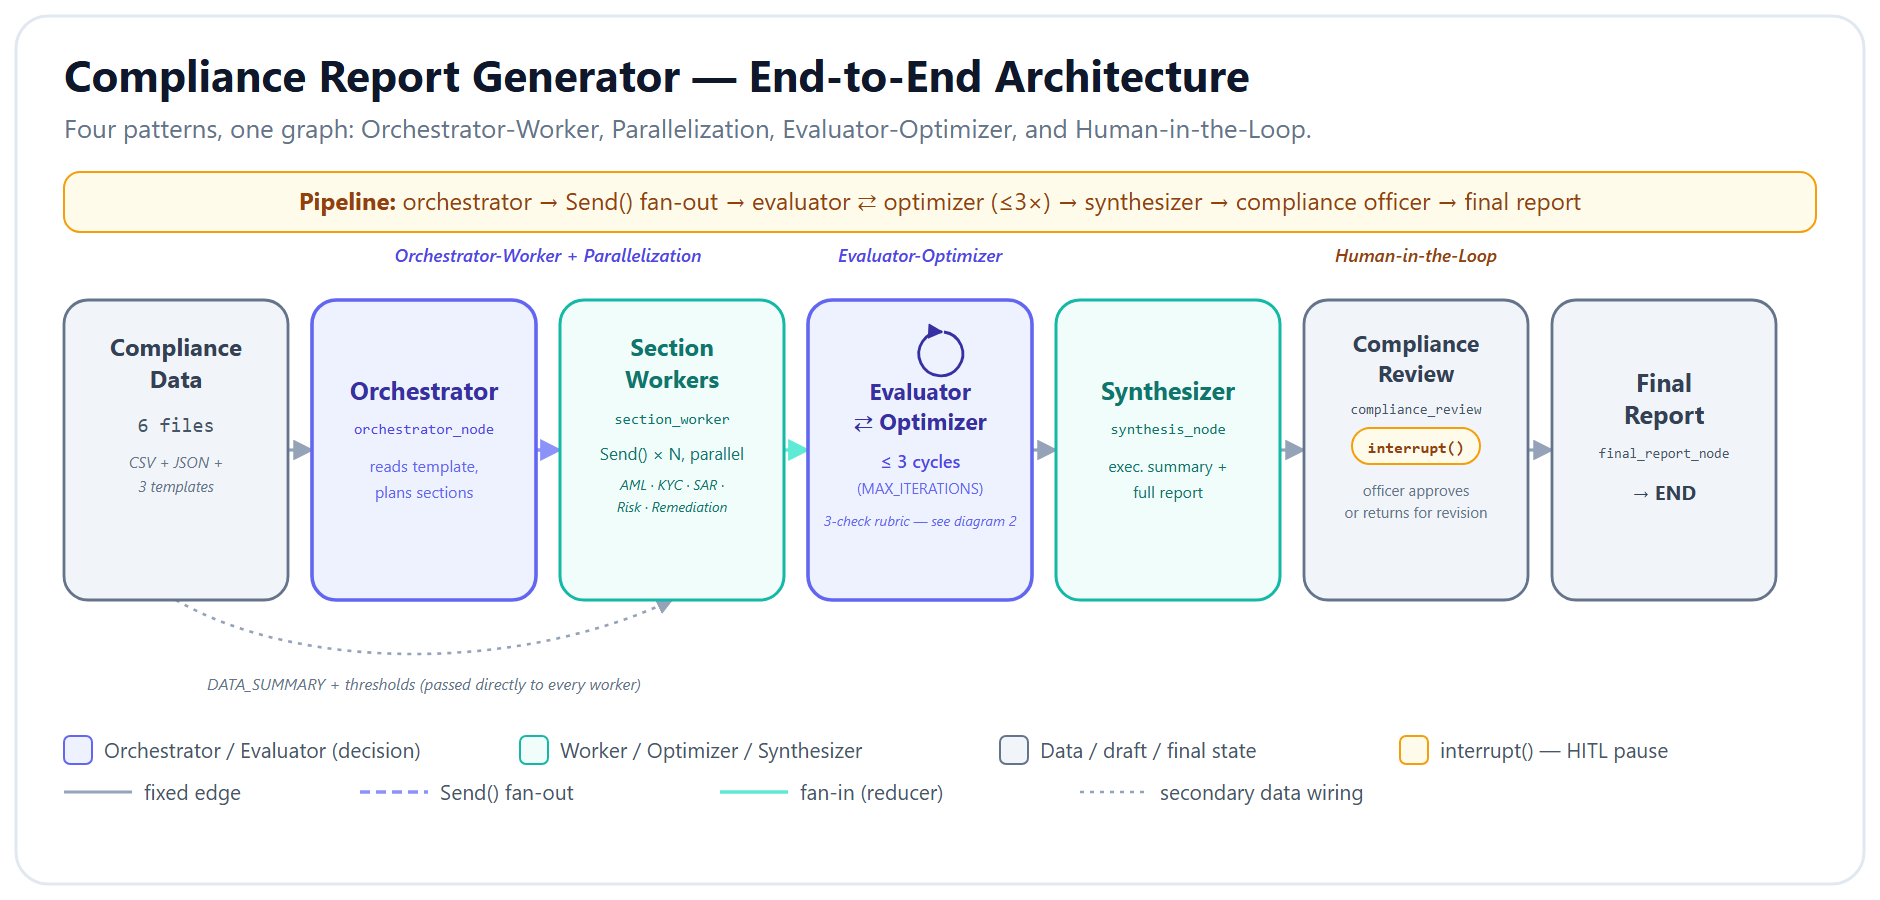

**Figure — Four patterns, one graph.** Orchestrator-Worker and Parallelization draft the sections in parallel; Evaluator-Optimizer polishes each one; Human-in-the-Loop holds the line before anything reaches a regulator.

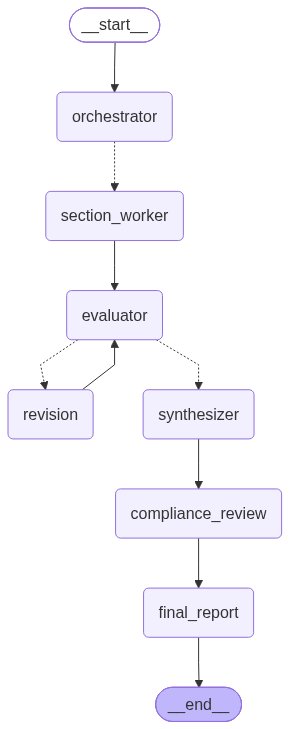

Graph visualization rendered.


In [22]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
    print("Graph visualization rendered.")
except Exception as error:
    # Fallback: print the Mermaid diagram source
    print("Could not render PNG. Mermaid diagram source:")
    print(graph.get_graph().draw_mermaid())

---

## Section 20: Run the FinCEN Report --- Main Demo

This is the primary demonstration. We generate a FinCEN BSA/AML quarterly compliance report for Q4 2025.

### What to Watch For

1. **Orchestrator** parses the FinCEN template (10 sections) and creates a plan
2. **Fan-out** dispatches 5+ parallel workers via `Send()`
3. **Workers** draft sections using real data from `DATA_SUMMARY`
4. **Evaluator** validates each section (watch for PASS/FAIL on 3 checks)
5. **Revision loop** fixes any failures (may iterate up to 3 times)
6. **Synthesizer** assembles the full report with executive summary
7. **HITL interrupt** pauses for compliance officer review

In [23]:
# =====================================================================
# STEP 1: Invoke the graph for FinCEN report
# =====================================================================
#
# BUGFIX NOTE: A known LangGraph + InMemorySaver interaction can raise
# "TypeError: Type is not msgpack serializable: Send" when the stream loop
# tries to checkpoint residual Send dispatches after reaching an interrupt.
# The state at the interrupt point is ALREADY persisted correctly --- only
# the trailing write fails. We catch that specific error so the notebook
# continues cleanly. In production, use a checkpointer with a serializer
# that handles Send objects (e.g., SqliteSaver with a custom serde).
# =====================================================================

thread_config = {"configurable": {"thread_id": "fincen-q4-2025"}}

initial_state = {
    "regulator": "FinCEN",
    "quarter": "Q4 2025",
    "template": fincen_template,
    "section_plan": [],
    "section_drafts": [],
    "evaluation_results": [],
    "sections_needing_revision": [],
    "iteration_count": 0,
    "approved_sections": [],
    "executive_summary": "",
    "full_report": "",
    "compliance_officer_notes": "",
    "hitl_approved": False,
    "acknowledged_warnings": [],
    "unresolved_sections": [],
    "final_report": "",
}

print("Starting FinCEN BSA/AML report generation...")
print(f"Regulator: FinCEN")
print(f"Quarter:   Q4 2025")
print(f"Template:  {len(fincen_template):,} chars, ~10 sections")
print()

start_time = time.time()

try:
    for event in graph.stream(initial_state, config=thread_config, stream_mode="updates"):
        for node_name, node_output in event.items():
            elapsed = time.time() - start_time
            print(f"\n[{elapsed:.1f}s] Node completed: {node_name}")
except TypeError as error:
    # Known benign post-interrupt serialization artifact. State is safe.
    if "msgpack serializable" in str(error) and "Send" in str(error):
        print(f"\n(Known msgpack/Send artifact after HITL pause --- state is intact.)")
    else:
        raise

elapsed = time.time() - start_time
print(f"\n{'='*60}")
print(f"Graph paused at HITL interrupt after {elapsed:.1f} seconds")
print(f"{'='*60}")


Starting FinCEN BSA/AML report generation...
Regulator: FinCEN
Quarter:   Q4 2025
Template:  5,406 chars, ~10 sections


ORCHESTRATOR: Planning FinCEN report for Q4 2025



Planned 8 sections:
  1. [AML] Section 1: AML Transaction Monitoring
     Data: ['aml_monitoring'] | Ref: 31 CFR 1020.210 (AML Program Requirements)
  2. [SAR] Section 2: Suspicious Activity Reporting (SAR)
     Data: ['sar_filings'] | Ref: 31 CFR 1020.320 (Suspicious Activity Reports)
  3. [AML] Section 3: Currency Transaction Reporting (CTR)
     Data: ['aml_monitoring'] | Ref: 31 U.S.C. 5313; implementing regulations at 31 CFR 1010.311 (Currency Transaction Reports)
  4. [KYC] Section 4: Customer Due Diligence (CDD)
     Data: ['kyc_cdd'] | Ref: 31 CFR 1020.220 (Customer Due Diligence / Beneficial Ownership Rule)
  5. [RISK] Section 5: Risk Assessment
     Data: ['risk_assessment'] | Ref: 31 U.S.C. 5318(h) (Risk‑based AML program requirement)
  6. [REMEDIATION] Section 6: Internal Controls and Audit
     Data: ['remediation', 'aml_monitoring', 'kyc_cdd'] | Ref: 31 CFR 1020.210 (Independent Testing & Internal Controls)
  7. [REMEDIATION] Section 7: Prior Findings Remediation
     Da

  WORKER [AML]: Completed 'Section 3: Currency Transaction Reporting (CTR)' (2377 chars, 4 metrics, confidence=1.00)


  WORKER [SAR]: Completed 'Section 2: Suspicious Activity Reporting (SAR)' (2561 chars, 15 metrics, confidence=1.00)

[58.9s] Node completed: section_worker

[58.9s] Node completed: section_worker


  WORKER [KYC]: Completed 'Section 4: Customer Due Diligence (CDD)' (3143 chars, 12 metrics, confidence=1.00)

[60.2s] Node completed: section_worker
  WORKER [AML]: Completed 'Section 1: AML Transaction Monitoring' (3757 chars, 12 metrics, confidence=1.00)

[60.2s] Node completed: section_worker


...

  WORKER [REMEDIATION]: Completed 'Section 6: Internal Controls and Audit' (3925 chars, 31 metrics, confidence=0.98)

[62.9s] Node completed: section_worker
  WORKER [RISK]: Completed 'Section 8: Regulatory Changes and Adaptations' (3733 chars, 25 metrics, confidence=1.00)

[63.0s] Node completed: section_worker

EVALUATOR: Checking 8 section drafts (skipping 0 already approved)
Iteration: 1


  Evaluating: Section 1: AML Transaction Monitoring...
    [FAIL] Numerical=FAIL | Terminology=OK | CrossRef=OK
    Feedback: Numerical accuracy issues (numbers in the narrative that are not present in the provided DATA_SUMMARY and appear to be i...
  Evaluating: Section 2: Suspicious Activity Reporting (SAR)...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Section 3: Currency Transaction Reporting (CTR)...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Section 4: Customer Due Diligence (CDD)...
    [FAIL] Numerical=FAIL | Terminology=OK | CrossRef=OK
    Feedback: One numerical issue: the statement “KYC updates every 12 to 36 months depending on risk rating” is not supported by the ...
  Evaluating: Section 5: Risk Assessment...
    [FAIL] Numerical=FAIL | Terminology=OK | CrossRef=FAIL
    Feedback: Numerical Accuracy failures (numbers that are incorrect or not present in the provided DATA_SUMMARY):
- Low risk custome...
  Evaluating: Sect

  Revising: Section 1: AML Transaction Monitoring
  Feedback: Numerical accuracy issues (numbers in the narrative that are not present in the provided DATA_SUMMAR...
  Revised: Section 1: AML Transaction Monitoring (2870 chars, 14 metrics)
  Revising: Section 4: Customer Due Diligence (CDD)
  Feedback: One numerical issue: the statement “KYC updates every 12 to 36 months depending on risk rating” is n...
  Revised: Section 4: Customer Due Diligence (CDD) (3130 chars, 10 metrics)
  Revising: Section 5: Risk Assessment
  Feedback: Numerical Accuracy failures (numbers that are incorrect or not present in the provided DATA_SUMMARY)...
  Revised: Section 5: Risk Assessment (2911 chars, 6 metrics)
  Revising: Section 7: Prior Findings Remediation
  Feedback: Numerical accuracy failures:
- "...improve alert review within 48 hours as per regulatory expectatio...
  Revised: Section 7: Prior Findings Remediation (3713 chars, 25 metrics)

[111.3s] Node completed: revision

EVALUATOR: Checking 4 s

  Evaluating: Section 1: AML Transaction Monitoring...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Section 4: Customer Due Diligence (CDD)...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Section 5: Risk Assessment...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Section 7: Prior Findings Remediation...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK

  EVALUATOR SUMMARY: 4 newly passed, 0 need revision, 4 carried over as approved

  GATE: All sections passed evaluation!
        -> Routing to SYNTHESIZER

[123.0s] Node completed: evaluator

SYNTHESIZER: Assembling FinCEN report for Q4 2025
  Total unique sections: 8
  Approved:              8


  Executive summary: 3061 chars
  Full report: 28644 chars

[127.0s] Node completed: synthesizer

HITL: Awaiting compliance officer review...
  Regulator: FinCEN
  Quarter:   Q4 2025
  Sections:  8 total, 8 approved, 0 unresolved
  Report:    28,644 chars

  >>> Graph PAUSED --- waiting for Command(resume=...) <<<

[127.0s] Node completed: __interrupt__

Graph paused at HITL interrupt after 127.0 seconds


In [24]:
current_state = graph.get_state(thread_config)

drafts = current_state.values.get('section_drafts', [])
print(f"Number of successfully completed drafts: {len(drafts)}")

if drafts:
    print("Successfully completed sections:")
    for draft in drafts:
        print(f" - {draft['section_name']}")

print("\nPending tasks (nodes that were running or are next):")
print(current_state.next)


Number of successfully completed drafts: 8
Successfully completed sections:
 - Section 1: AML Transaction Monitoring
 - Section 2: Suspicious Activity Reporting (SAR)
 - Section 3: Currency Transaction Reporting (CTR)
 - Section 4: Customer Due Diligence (CDD)
 - Section 5: Risk Assessment
 - Section 6: Internal Controls and Audit
 - Section 7: Prior Findings Remediation
 - Section 8: Regulatory Changes and Adaptations

Pending tasks (nodes that were running or are next):
('compliance_review',)


In [25]:
current_state = graph.get_state({"configurable": {"thread_id": "fincen-q4-2025"}})
report_content = current_state.values.get("full_report", "Report not found or not yet generated.")
print(report_content)

# FinCEN Quarterly Compliance Report
## Q4 2025 | MidwestBank
## Prepared: 2026-09-30

---

## Executive Summary

Executive Summary – Q4 2025 FinCEN Compliance Report  
MidwestBank, with total assets of $8 billion and a network of 42 branches supported by 500 employees, continues to demonstrate a robust commitment to AML compliance. This report summarizes key compliance metrics, identifies areas requiring immediate attention, and assesses the institution’s forward-looking compliance posture.

Section 1: AML Transaction Monitoring  
During Q4 2025, MidwestBank monitored 50,000 transactions totaling approximately $311.3 million. Suspicious transactions numbered 1,053, representing 2.11% of total transactions, involving $5.2 million. Transaction types were well-distributed across transfers, deposits, ATM activities, checks, withdrawals, and wires, with transfers leading at 8,578 transactions. The bank identified 4,347 CTR-eligible transactions exceeding the $10,000 threshold, reflecting v

### Step 2: Inspect the State Before HITL Review

Before the compliance officer decides, let us inspect the current graph state to see what was produced.

In [26]:
# =====================================================================
# STEP 2: Inspect the interrupted state
# =====================================================================

current_state = graph.get_state(thread_config)

print("=" * 60)
print("CURRENT GRAPH STATE (paused at HITL)")
print("=" * 60)

state_values = current_state.values

print(f"\nRegulator:        {state_values.get('regulator')}")
print(f"Quarter:          {state_values.get('quarter')}")
print(f"Sections planned: {len(state_values.get('section_plan', []))}")
print(f"Sections drafted: {len(state_values.get('section_drafts', []))}")
print(f"Sections approved:{len(state_values.get('approved_sections', []))}")
print(f"Iterations used:  {state_values.get('iteration_count', 0)}")
print(f"Report length:    {len(state_values.get('full_report', '')):,} chars")

# Show the section plan
print(f"\n--- Section Plan ---")
for position, section in enumerate(state_values.get("section_plan", []), 1):
    print(f"  {position}. [{section['worker_type'].upper()}] {section['section_name']}")

# Show evaluation results summary
print(f"\n--- Evaluation Results ---")
for result in state_values.get("evaluation_results", []):
    status = "PASS" if result.get("overall_pass") else "FAIL"
    print(f"  [{status}] {result.get('section_name')}")

# Show executive summary preview
executive_summary = state_values.get("executive_summary", "")
if executive_summary:
    print(f"\n--- Executive Summary Preview (first 500 chars) ---")
    print(executive_summary[:500])
    print("...")

CURRENT GRAPH STATE (paused at HITL)

Regulator:        FinCEN
Quarter:          Q4 2025
Sections planned: 8
Sections drafted: 8
Sections approved:8
Iterations used:  2
Report length:    28,644 chars

--- Section Plan ---
  1. [AML] Section 1: AML Transaction Monitoring
  2. [SAR] Section 2: Suspicious Activity Reporting (SAR)
  3. [AML] Section 3: Currency Transaction Reporting (CTR)
  4. [KYC] Section 4: Customer Due Diligence (CDD)
  5. [RISK] Section 5: Risk Assessment
  6. [REMEDIATION] Section 6: Internal Controls and Audit
  7. [REMEDIATION] Section 7: Prior Findings Remediation
  8. [RISK] Section 8: Regulatory Changes and Adaptations

--- Evaluation Results ---
  [PASS] Section 1: AML Transaction Monitoring
  [PASS] Section 4: Customer Due Diligence (CDD)
  [PASS] Section 5: Risk Assessment
  [PASS] Section 7: Prior Findings Remediation

--- Executive Summary Preview (first 500 chars) ---
Executive Summary – Q4 2025 FinCEN Compliance Report  
MidwestBank, with total assets of 

### Step 3: Compliance Officer Approves the Report

In a production system, this would be a web form or Slack notification. Here we simulate the compliance officer reviewing the executive summary and approving with notes.

We use `Command(resume={...})` to inject the officer's decision and restart the graph from the interrupt point.

In [27]:
# =====================================================================
# STEP 3: Compliance officer approves the report
# =====================================================================
#
# The resume payload accepts `acknowledged_warnings` --- a list of
# section names the officer explicitly accepts despite not passing full
# validation. If the run has unresolved sections and they are NOT listed here,
# the final report will carry a prominent disclaimer banner.
# =====================================================================

# Check current state to see if there are any unresolved sections to acknowledge
pre_resume_state = graph.get_state(thread_config)
unresolved = pre_resume_state.values.get("unresolved_sections", [])

print("Compliance officer reviewing report...")
if unresolved:
    print(f"!! {len(unresolved)} unresolved section(s) flagged: {unresolved}")
    print("Officer will acknowledge them to proceed.")
else:
    print("All sections passed evaluation.")
print("Decision: APPROVED with notes\n")

# Resume the graph with the officer's decision
for event in graph.stream(
    Command(resume={
        "approved": True,
        "notes": (
            "Report approved for submission. Minor note: ensure the SAR timeliness "
            "section explicitly references the 30-day initial filing deadline per "
            "31 CFR 1020.320(b)(3). Add a footnote about the Q3 2025 regulatory "
            "guidance update from FinCEN Advisory FIN-2025-A001."
        ),
        # Acknowledge whatever unresolved sections exist (if any).
        # In production, each name in this list would be reviewed individually
        # with justification notes per section.
        "acknowledged_warnings": unresolved,
    }),
    config=thread_config,
    stream_mode="updates",
):
    for node_name, node_output in event.items():
        print(f"Node completed: {node_name}")

print("\nFinCEN report generation complete!")


Compliance officer reviewing report...
All sections passed evaluation.
Decision: APPROVED with notes


HITL: Awaiting compliance officer review...
  Regulator: FinCEN
  Quarter:   Q4 2025
  Sections:  8 total, 8 approved, 0 unresolved
  Report:    28,644 chars

  >>> Graph PAUSED --- waiting for Command(resume=...) <<<

  Officer decision: APPROVED
  Officer notes: Report approved for submission. Minor note: ensure the SAR timeliness section explicitly references the 30-day initial filing deadline per 31 CFR 1020.320(b)(3). Add a footnote about the Q3 2025 regul
Node completed: compliance_review

FINAL REPORT: Assembling submission-ready document
  Status: APPROVED
  Final report length: 29,009 chars
Node completed: final_report

FinCEN report generation complete!


In [28]:
# =====================================================================
# STEP 4: Display the final report
# =====================================================================

final_state = graph.get_state(thread_config)
final_report = final_state.values.get("final_report", "")

print("=" * 60)
print("FINAL FINCEN REPORT")
print("=" * 60)
print(f"Length: {len(final_report):,} characters")
print(f"HITL Approved: {final_state.values.get('hitl_approved')}")
print(f"Officer Notes: {final_state.values.get('compliance_officer_notes', '')[:200]}")
print("\n--- Report Preview (first 2000 chars) ---\n")
print(final_report[:2000])
print("\n... [truncated for display] ...")

FINAL FINCEN REPORT
Length: 29,009 characters
HITL Approved: True
Officer Notes: Report approved for submission. Minor note: ensure the SAR timeliness section explicitly references the 30-day initial filing deadline per 31 CFR 1020.320(b)(3). Add a footnote about the Q3 2025 regul

--- Report Preview (first 2000 chars) ---

# FinCEN Quarterly Compliance Report
## Q4 2025 | MidwestBank
## Prepared: 2026-09-30

---

## Executive Summary

Executive Summary – Q4 2025 FinCEN Compliance Report  
MidwestBank, with total assets of $8 billion and a network of 42 branches supported by 500 employees, continues to demonstrate a robust commitment to AML compliance. This report summarizes key compliance metrics, identifies areas requiring immediate attention, and assesses the institution’s forward-looking compliance posture.

Section 1: AML Transaction Monitoring  
During Q4 2025, MidwestBank monitored 50,000 transactions totaling approximately $311.3 million. Suspicious transactions numbered 1,053,

---

## Section 21: Run the OCC Report --- Template Adaptation Demo

Now we demonstrate that the **same system adapts to a different regulator's template**. The OCC template has a different structure (10 Parts vs. FinCEN's 10 Sections), different terminology ("Management Summary" vs. "Executive Summary"), and additional topics (consumer protection, cybersecurity, enterprise risk).

The orchestrator will:
- Parse the OCC template's unique structure
- Create a different section plan with different worker assignments
- Adapt the regulatory references to OCC-specific citations

In [29]:
# =====================================================================
# OCC REPORT --- different template, same system
# (Same msgpack/Send guard as the FinCEN run above.)
# =====================================================================

occ_config = {"configurable": {"thread_id": "occ-q4-2025"}}

occ_initial_state = {
    "regulator": "OCC",
    "quarter": "Q4 2025",
    "template": occ_template,
    "section_plan": [],
    "section_drafts": [],
    "evaluation_results": [],
    "sections_needing_revision": [],
    "iteration_count": 0,
    "approved_sections": [],
    "executive_summary": "",
    "full_report": "",
    "compliance_officer_notes": "",
    "hitl_approved": False,
    "acknowledged_warnings": [],
    "unresolved_sections": [],
    "final_report": "",
}

print("Starting OCC Safety & Soundness report generation...")
print(f"Template: {len(occ_template):,} chars, ~10 parts")
print()

start_time = time.time()

try:
    for event in graph.stream(occ_initial_state, config=occ_config, stream_mode="updates"):
        for node_name, node_output in event.items():
            elapsed = time.time() - start_time
            print(f"[{elapsed:.1f}s] Node completed: {node_name}")
except TypeError as error:
    if "msgpack serializable" in str(error) and "Send" in str(error):
        print(f"\n(Known msgpack/Send artifact after HITL pause --- state is intact.)")
    else:
        raise

elapsed = time.time() - start_time
print(f"\nGraph paused at HITL interrupt after {elapsed:.1f} seconds")


Starting OCC Safety & Soundness report generation...
Template: 5,530 chars, ~10 parts


ORCHESTRATOR: Planning OCC report for Q4 2025



Planned 14 sections:
  1. [RISK] Part I: Compliance Management System
     Data: ['institution', 'risk_assessment'] | Ref: 12 CFR 30
  2. [AML] Part II.A: BSA/AML Program Assessment
     Data: ['aml_monitoring', 'risk_assessment', 'institution'] | Ref: 31 CFR 1020.210
  3. [AML] Part II.B: Transaction Monitoring
     Data: ['aml_monitoring'] | Ref: 31 CFR 1020.210
  4. [KYC] Part II.C: Customer Identification Program (CIP)
     Data: ['kyc_cdd', 'institution'] | Ref: 31 CFR 1020.220
  5. [KYC] Part II.D: Customer Due Diligence
     Data: ['kyc_cdd'] | Ref: 31 CFR 1010.230
  6. [SAR] Part II.E: Suspicious Activity Reporting
     Data: ['sar_filings', 'aml_monitoring'] | Ref: 31 CFR 1020.320
  7. [RISK] Part III: Consumer Protection Compliance
     Data: ['risk_assessment', 'institution', 'remediation'] | Ref: 12 CFR 1002 (Reg B)
  8. [RISK] Part IV: Information Security and Cybersecurity
     Data: ['risk_assessment', 'institution'] | Ref: 16 CFR Part 314 (GLBA Safeguards Rule)
  9. [R

  WORKER [RISK]: Completed 'Part IV: Information Security and Cybersecurity' (2763 chars, 8 metrics, confidence=1.00)
  WORKER [RISK]: Drafting 'Part IX: Consumer Complaints'...
[52.2s] Node completed: section_worker


  WORKER [KYC]: Completed 'Part II.D: Customer Due Diligence' (2867 chars, 10 metrics, confidence=1.00)
  WORKER [RISK]: Drafting 'Part X: Training and Competency'...
[52.6s] Node completed: section_worker
  WORKER [AML]: Completed 'Part II.B: Transaction Monitoring' (2674 chars, 17 metrics, confidence=1.00)
[52.7s] Node completed: section_worker
  WORKER [KYC]: Completed 'Part II.C: Customer Identification Program (CIP)' (2866 chars, 10 metrics, confidence=1.00)
[52.7s] Node completed: section_worker


  WORKER [AML]: Completed 'Part II.A: BSA/AML Program Assessment' (2916 chars, 26 metrics, confidence=1.00)
[53.8s] Node completed: section_worker


...

  WORKER [RISK]: Completed 'Part X: Training and Competency' (2428 chars, 6 metrics, confidence=1.00)
[59.4s] Node completed: section_worker

EVALUATOR: Checking 14 section drafts (skipping 0 already approved)
Iteration: 1


  Evaluating: Part I: Compliance Management System...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part II.A: BSA/AML Program Assessment...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part II.B: Transaction Monitoring...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part II.C: Customer Identification Program (CIP)...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part II.D: Customer Due Diligence...
    [FAIL] Numerical=FAIL | Terminology=OK | CrossRef=FAIL
    Feedback: 1) Numerical error: The narrative states '34.74% have expired KYC' but DATA_SUMMARY shows 1,637 expired out of 5,000, wh...
  Evaluating: Part II.E: Suspicious Activity Reporting...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part III: Consumer Protection Compliance...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part IV: Information Security and Cybersecurity...
    [PASS] Nume

  Revising: Part II.D: Customer Due Diligence
  Feedback: 1) Numerical error: The narrative states '34.74% have expired KYC' but DATA_SUMMARY shows 1,637 expi...
  Revised: Part II.D: Customer Due Diligence (2896 chars, 13 metrics)
  Revising: Part V: Internal Audit and Testing
  Feedback: Terminology error: The opening phrase "BSA/AML requirements under 12 CFR 30" is inaccurate. The Bank...
  Revised: Part V: Internal Audit and Testing (3473 chars, 25 metrics)
  Revising: Part VIII: Enterprise Risk Management
  Feedback: Numerical accuracy failures (numbers in the narrative that do not appear in the provided DATA_SUMMAR...
  Revised: Part VIII: Enterprise Risk Management (2947 chars, 15 metrics)
  Revising: Part IX: Consumer Complaints
  Feedback: Numerical accuracy issues:
- The draft cites specific KYC refresh cycles (36 months for low risk, 24...
  Revised: Part IX: Consumer Complaints (1896 chars, 6 metrics)
[136.1s] Node completed: revision

EVALUATOR: Checking 4 section drafts (

  Evaluating: Part II.D: Customer Due Diligence...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part V: Internal Audit and Testing...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part VIII: Enterprise Risk Management...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK
  Evaluating: Part IX: Consumer Complaints...
    [PASS] Numerical=OK | Terminology=OK | CrossRef=OK

  EVALUATOR SUMMARY: 4 newly passed, 0 need revision, 10 carried over as approved

  GATE: All sections passed evaluation!
        -> Routing to SYNTHESIZER
[147.7s] Node completed: evaluator

SYNTHESIZER: Assembling OCC report for Q4 2025
  Total unique sections: 14
  Approved:              14


  Executive summary: 3180 chars
  Full report: 45584 chars
[152.7s] Node completed: synthesizer

HITL: Awaiting compliance officer review...
  Regulator: OCC
  Quarter:   Q4 2025
  Sections:  14 total, 14 approved, 0 unresolved
  Report:    45,584 chars

  >>> Graph PAUSED --- waiting for Command(resume=...) <<<
[152.7s] Node completed: __interrupt__

Graph paused at HITL interrupt after 152.7 seconds


In [30]:
# ---- OCC: Quick approve and display ----

pre_resume_state = graph.get_state(occ_config)
unresolved = pre_resume_state.values.get("unresolved_sections", [])

print("Compliance officer approving OCC report...\n")
if unresolved:
    print(f"!! {len(unresolved)} unresolved OCC section(s) flagged: {unresolved}")
    print("Officer will acknowledge them with specific notes.\n")

for event in graph.stream(
    Command(resume={
        "approved": True,
        "notes": (
            "OCC report approved. Ensure Part VII (Prior Examination Findings) "
            "addresses all outstanding MRAs. "
            + (f"Unresolved sections reviewed manually: {unresolved}." if unresolved else "")
        ),
        "acknowledged_warnings": unresolved,
    }),
    config=occ_config,
    stream_mode="updates",
):
    for node_name, _ in event.items():
        print(f"Node completed: {node_name}")

# Show OCC section plan for comparison
occ_state = graph.get_state(occ_config)
print(f"\n--- OCC Section Plan (compare with FinCEN above) ---")
for position, section in enumerate(occ_state.values.get("section_plan", []), 1):
    print(f"  {position}. [{section['worker_type'].upper()}] {section['section_name']}")

occ_report = occ_state.values.get("final_report", "")
print(f"\nOCC report length: {len(occ_report):,} chars")
print(f"\n--- OCC Report Preview (first 1000 chars) ---")
print(occ_report[:1000])
print("\n... [truncated] ...")


Compliance officer approving OCC report...


HITL: Awaiting compliance officer review...
  Regulator: OCC
  Quarter:   Q4 2025
  Sections:  14 total, 14 approved, 0 unresolved
  Report:    45,584 chars

  >>> Graph PAUSED --- waiting for Command(resume=...) <<<

  Officer decision: APPROVED
  Officer notes: OCC report approved. Ensure Part VII (Prior Examination Findings) addresses all outstanding MRAs. 
Node completed: compliance_review

FINAL REPORT: Assembling submission-ready document
  Status: APPROVED
  Final report length: 45,790 chars
Node completed: final_report

--- OCC Section Plan (compare with FinCEN above) ---
  1. [RISK] Part I: Compliance Management System
  2. [AML] Part II.A: BSA/AML Program Assessment
  3. [AML] Part II.B: Transaction Monitoring
  4. [KYC] Part II.C: Customer Identification Program (CIP)
  5. [KYC] Part II.D: Customer Due Diligence
  6. [SAR] Part II.E: Suspicious Activity Reporting
  7. [RISK] Part III: Consumer Protection Compliance
  8. [RISK] Par

---

## Section 22: Time Travel Demo --- Checkpoint History

One of the most powerful features of LangGraph's checkpointing is **time travel**: the ability to inspect past states of the graph. This is invaluable for:

- **Auditing:** Regulators may ask "show me the intermediate drafts before the evaluator revised them"
- **Debugging:** If a report has an issue, you can trace it back to the specific worker and iteration
- **Compliance documentation:** Maintaining a complete chain of custody for the report generation process

Let us explore the FinCEN report's checkpoint history.

In [31]:
# =====================================================================
# TIME TRAVEL: Inspect checkpoint history for the FinCEN report
# =====================================================================

print("=" * 60)
print("TIME TRAVEL: FinCEN Report Checkpoint History")
print("=" * 60)

# Get all state history entries
history = list(graph.get_state_history(thread_config))

print(f"\nTotal checkpoints: {len(history)}")
print(f"\n{'Step':<6} {'Node(s) Next':<30} {'Sections Drafted':<20} {'Iterations':<12} {'Report Len'}")
print("-" * 90)

for step_index, snapshot in enumerate(history):
    snapshot_values = snapshot.values
    next_nodes = [task[0] if isinstance(task, tuple) else str(task)
                  for task in (snapshot.next or [])]
    next_node_label = ", ".join(next_nodes) if next_nodes else "(terminal)"
    draft_count = len(snapshot_values.get("section_drafts", []))
    iterations_used = snapshot_values.get("iteration_count", 0)
    report_length = len(snapshot_values.get("full_report", ""))

    print(f"{step_index:<6} {next_node_label:<30} {draft_count:<20} {iterations_used:<12} {report_length:,}")

print(f"\nYou can replay from any checkpoint by using graph.get_state_history()")
print("and passing a specific checkpoint's config to graph.invoke().")

TIME TRAVEL: FinCEN Report Checkpoint History

Total checkpoints: 10

Step   Node(s) Next                   Sections Drafted     Iterations   Report Len
------------------------------------------------------------------------------------------
0      (terminal)                     8                    2            28,644
1      final_report                   8                    2            28,644
2      compliance_review              8                    2            28,644
3      synthesizer                    8                    2            0
4      evaluator                      8                    1            0
5      revision                       8                    1            0
6      evaluator                      8                    0            0
7      section_worker, section_worker, section_worker, section_worker, section_worker, section_worker, section_worker, section_worker 0                    0            0
8      orchestrator                   0              

---

## Section 23: Multi-Model Comparison (Bonus)

Let us compare how different models handle the same section-writing task. We will draft a single AML section using both `gpt-5-mini` and `gpt-4.1-mini` and compare the results.

This helps teams make informed decisions about model selection for different roles in their agentic pipelines.

In [32]:
# =====================================================================
# MULTI-MODEL COMPARISON: Same section, different models
# =====================================================================

comparison_section = {
    "section_name": "AML Transaction Monitoring",
    "description": "Overview of transaction monitoring system performance, alert statistics, and AML program effectiveness.",
    "data_sources": ["aml_monitoring"],
    "worker_type": "aml",
    "regulatory_reference": "31 CFR 1020.210",
}

comparison_messages = [
    SystemMessage(content=WORKER_PROMPTS["aml"]),
    HumanMessage(content=f"""Draft the AML Transaction Monitoring section for a FinCEN quarterly report (Q4 2025).

DATA:
{json.dumps(DATA_SUMMARY['aml_monitoring'], indent=2)}

Keep it concise (200-300 words). Return a SectionDraft.""")
]

print("Comparing models on AML Transaction Monitoring section...\n")

# Model 1: gpt-4.1-mini (worker model)
start_time = time.time()
model_gpt41_mini = ChatOpenAI(model="gpt-4.1-mini", temperature=0.2)
result_gpt41_mini = model_gpt41_mini.with_structured_output(
    SectionDraft, method="function_calling").invoke(comparison_messages)
elapsed_gpt41_mini = time.time() - start_time

# Model 2: gpt-5-mini (reasoning model)
start_time = time.time()
model_gpt5_mini = ChatOpenAI(model="gpt-5-mini")
result_gpt5_mini = model_gpt5_mini.with_structured_output(
    SectionDraft, method="function_calling").invoke(comparison_messages)
elapsed_gpt5_mini = time.time() - start_time

print(f"{'Metric':<30} {'gpt-4.1-mini':<20} {'gpt-5-mini':<20}")
print("-" * 70)
print(f"{'Latency':<30} {elapsed_gpt41_mini:.2f}s{'':<14} {elapsed_gpt5_mini:.2f}s")
print(f"{'Content length':<30} {len(result_gpt41_mini.content):<20} {len(result_gpt5_mini.content):<20}")
print(f"{'Key metrics count':<30} {len(result_gpt41_mini.key_metrics):<20} {len(result_gpt5_mini.key_metrics):<20}")
print(f"{'Confidence':<30} {result_gpt41_mini.confidence:<20.2f} {result_gpt5_mini.confidence:<20.2f}")
print(f"{'Data citations':<30} {len(result_gpt41_mini.data_citations):<20} {len(result_gpt5_mini.data_citations):<20}")

print(f"\n--- gpt-4.1-mini output (first 400 chars) ---")
print(result_gpt41_mini.content[:400])
print(f"\n--- gpt-5-mini output (first 400 chars) ---")
print(result_gpt5_mini.content[:400])

print(f"\n--- Takeaway ---")
print("gpt-4.1-mini: Faster, cost-effective, good for templated writing tasks.")
print("gpt-5-mini:   Stronger reasoning, better for planning and evaluation tasks.")
print("Our architecture uses each model where it excels.")


Comparing models on AML Transaction Monitoring section...



Metric                         gpt-4.1-mini         gpt-5-mini          
----------------------------------------------------------------------
Latency                        3.16s               12.70s
Content length                 1378                 1382                
Key metrics count              13                   13                  
Confidence                     1.00                 0.94                
Data citations                 8                    8                   

--- gpt-4.1-mini output (first 400 chars) ---
During the fourth quarter of 2025, the bank processed a total of 50,000 transactions amounting to $311,260,070.15. Our BSA transaction monitoring system identified 1,053 suspicious transactions, representing 2.11% of total transactions, with a combined suspicious amount of $5,214,006.53. These alerts were generated through our risk-based monitoring protocols, which include real-time and batch tran

--- gpt-5-mini output (first 400 chars) ---
During Q4 202

---

## Section 24: Full Pipeline Metrics

Let us summarize the key metrics from both report runs to demonstrate the system's capabilities.

In [33]:
# =====================================================================
# PIPELINE METRICS SUMMARY
# =====================================================================

fincen_state = graph.get_state(thread_config).values
occ_state_values = graph.get_state(occ_config).values

print("=" * 70)
print("COMPLIANCE REPORT GENERATOR --- PIPELINE METRICS")
print("=" * 70)

print(f"\n{'Metric':<40} {'FinCEN Report':<20} {'OCC Report':<20}")
print("-" * 80)
print(f"{'Regulator':<40} {'FinCEN':<20} {'OCC':<20}")
print(f"{'Quarter':<40} {'Q4 2025':<20} {'Q4 2025':<20}")
print(f"{'Sections planned':<40} {len(fincen_state.get('section_plan', [])):<20} {len(occ_state_values.get('section_plan', [])):<20}")
print(f"{'Sections drafted':<40} {len(fincen_state.get('section_drafts', [])):<20} {len(occ_state_values.get('section_drafts', [])):<20}")
print(f"{'Evaluation iterations':<40} {fincen_state.get('iteration_count', 0):<20} {occ_state_values.get('iteration_count', 0):<20}")
print(f"{'HITL approved':<40} {str(fincen_state.get('hitl_approved')):<20} {str(occ_state_values.get('hitl_approved')):<20}")
print(f"{'Final report length':<40} {len(fincen_state.get('final_report', '')):>10,} chars   {len(occ_state_values.get('final_report', '')):>10,} chars")

print(f"\n--- Evaluation Results (FinCEN) ---")
for result in fincen_state.get("evaluation_results", []):
    status = "PASS" if result.get("overall_pass") else "FAIL"
    print(f"  [{status}] {result.get('section_name')}")

print(f"\n--- Evaluation Results (OCC) ---")
for result in occ_state_values.get("evaluation_results", []):
    status = "PASS" if result.get("overall_pass") else "FAIL"
    print(f"  [{status}] {result.get('section_name')}")

COMPLIANCE REPORT GENERATOR --- PIPELINE METRICS

Metric                                   FinCEN Report        OCC Report          
--------------------------------------------------------------------------------
Regulator                                FinCEN               OCC                 
Quarter                                  Q4 2025              Q4 2025             
Sections planned                         8                    14                  
Sections drafted                         8                    14                  
Evaluation iterations                    2                    2                   
HITL approved                            True                 True                
Final report length                          29,009 chars       45,790 chars

--- Evaluation Results (FinCEN) ---
  [PASS] Section 1: AML Transaction Monitoring
  [PASS] Section 4: Customer Due Diligence (CDD)
  [PASS] Section 5: Risk Assessment
  [PASS] Section 7: Prior Findings Remedia

---

## Section 25: Conclusion

---

### Key Takeaways

1. **Orchestrator-Worker with `Send` API** enables dynamic, parallel section generation. The orchestrator never writes sections itself --- it plans and delegates, achieving true separation of concerns.

2. **Evaluator-Optimizer loop with specific feedback** ensures numerical accuracy in every section. Generic feedback ("improve quality") would not work --- the evaluator must identify exactly which number is wrong and what it should be.

3. **`Annotated[list, merge_drafts_by_name]` reducer** is essential for parallel fan-in. Without a reducer, LangGraph rejects the parallel workers' updates (`InvalidUpdateError`); with plain `operator.add`, a revised draft would be appended beside the original. The reducer is the mechanism that makes fan-out/fan-in safe.

4. **Human-in-the-Loop is non-negotiable in regulated domains.** Banking regulators require human attestation on compliance reports. The `interrupt()` / `Command(resume=...)` pattern integrates this seamlessly.

5. **Different LLM configurations serve different roles.** Reasoning models (`gpt-5-mini`) excel at planning and evaluation. Writing models (`gpt-4.1-mini` with temperature) produce natural regulatory prose. Matching the model to the task optimizes both quality and cost.

6. **PII redaction is a defense-in-depth layer.** Even though workers only receive aggregate statistics, the redaction function catches any PII that might leak through LLM responses.

7. **Time travel (checkpoint history)** provides a complete audit trail of the report generation process --- critical for regulatory inquiries.

---

### Architecture Patterns Recap

| Pattern | Where Used | Key LangGraph API |
|---------|-----------|------------------|
| Orchestrator-Worker (#4) | Orchestrator plans, workers execute | `Send("node_name", state)` |
| Evaluator-Optimizer (#5) | 3-check validation with revision loop | Conditional edge + iteration counter |
| Parallelization (#3) | 5+ workers execute simultaneously | `Send()` + `Annotated[list, merge_drafts_by_name]` |
| Human-in-the-Loop (#6) | Compliance officer review | `interrupt()` + `Command(resume=...)` |

---

### Try it yourself

1. **Reflect** on which pattern (Orchestrator-Worker, Evaluator-Optimizer, Parallelization, or HITL) you found most impactful for production compliance systems and why
2. **Challenge extension:** Modify the system to generate a State Banking Department report (the third template) and compare the orchestrator's section plans across all three regulators

---

### What Comes Next

You can extend this compliance system with:
- **Model Context Protocol (MCP)** for connecting to external regulatory databases (Module 6's MCP & A2A lab)
- **Guardrails** for automated content safety and compliance checking (the input and output guardrails of Module 4's OpenAI Agents SDK lab)
- **Production deployment** considerations for a real banking environment
- **Tracing** of every node in LangSmith

---

*Four agentic patterns, one production-grade compliance system.*

---

## Section 26: Next Steps — Taking This Further

You have built a working multi-agent compliance report generator that demonstrates the orchestrator-worker, evaluator-optimizer, and human-in-the-loop patterns end-to-end, with real BFSI-shaped data and two distinct regulator templates. This is a solid portfolio project. Here are directions you can take it in to make it even stronger — tackle any one of these and the project starts to look like serious engineering work rather than a lab exercise.

**Hybrid validation.** Right now the numerical-accuracy check is an LLM asking another LLM. Replace it with a Python function that extracts every number from the draft, looks each one up in DATA_SUMMARY, and returns a deterministic pass/fail list. The LLM then only handles terminology and prose quality. This makes the pipeline cheaper, faster, and audit-friendly.

**Durable persistence.** Swap `InMemorySaver` for `SqliteSaver` or `PostgresSaver`. Now your runs survive restarts, you can reload a report mid-review the next day, and you have a queryable audit log of every node's inputs and outputs.

**Structured audit trail.** Add a node after `final_report` that writes a JSON manifest (timestamp, officer identity, section approvals, acknowledged warnings, model versions, token counts) to disk or a database. This is what turns the notebook into something a compliance team could actually defend during an examination.

**Retry and fallback.** Wrap each LLM call in a retry decorator with exponential backoff. Add a fallback to a secondary model or provider when OpenAI returns 5xx or hits a rate limit. The pipeline should not fail because of a transient API hiccup.

**Deterministic PII layer.** The current regex redactor is good defense-in-depth but not the primary control. Build a preprocessing step that anonymizes DATA_SUMMARY before it reaches any LLM, using Microsoft Presidio or a similar named-entity-recognition library for stronger guarantees.

**Web UI for the HITL step.** Replace the `Command(resume=...)` notebook pattern with a small FastAPI + HTML page where the compliance officer can actually read the report, view unresolved warnings in a side panel, acknowledge them with per-section justification, and sign off with authentication. This is the piece that makes it feel like a product.

**Evaluation harness.** Build a small test suite that feeds known-correct and known-incorrect drafts into the evaluator and measures precision/recall of the three checks. You can use this to tune prompts with confidence instead of guessing whether a change helped.

**Cost and latency telemetry.** Instrument each node with token counts, latency, and model used, and emit a summary at the end. With the parallel evaluator a single run should be well under 5 minutes; being able to prove that with numbers is the kind of thing hiring managers remember.

Pick one. Ship it. Each of these is a weekend's work and each one measurably strengthens the project.
